# Decay angle of the leading muon pair in a muon lepton jet

A lepton jet is a group of collimated muons, electrons or photons clustered into one object, the
signature of a light, highly boosted dark photon (Zd) decaying to a lepton pair.  A muon lepton
jet is built from muons, an electromagnetic lepton jet from electrons and photons.  A fake lepton
jet is one not produced by a dark-photon decay, for example two unrelated muons that happen to be
clustered together.

This study takes every muon lepton jet with at least two constituent muons and measures the decay
angle theta* of its two leading muons: the angle of the leading muon in the rest frame of the
pair, relative to the pair's direction in the laboratory (section a).  It compares |cos(theta*)|
between simulated signal, simulated background and collision data in a set of control regions
(CR) and validation regions (VR), and asks whether the angle separates genuine from fake muon
lepton jets.  Signal samples are labelled by the mass m_XX of the heavy bound state that decays to
two dark photons, the dark-photon mass m_Zd and the dark photon's proper decay length c tau.

All loading, normalisation and drawing lives in `_mulj_lib.py` in this directory, and each figure
comes from one function there.  Only the configuration cell below needs to change when the inputs
change; the sample lists are read from whatever is in the input directory.

The histograms come from three production campaigns run on Condor, listed under "Selections used
in this study".  The first campaign fills one entry per muon lepton jet and feeds sections a to h.
The pair campaign records the two muon lepton jets of a four-muon event together and feeds
section i.  The decay-plane campaign feeds section j, which adds the electron pair of an
electromagnetic lepton jet and the angle between the two lepton jets' decay planes.  Sections i
and j were added after the first campaign, and each reads its own merged files, set in its own
configuration cell.

Each section states what its figures show and what follows from them.  Section g collects the
caveats that apply to every figure, and section h states the verdict.

In [1]:
import os
import sys

# locate the study directory whether the notebook was started in it or from the repository root
_candidates = []
_walk = os.getcwd()
while True:
    _candidates.append(_walk)
    _candidates.append(os.path.join(_walk, "sidm", "studies", "mulj_decay_angle"))
    _parent = os.path.dirname(_walk)
    if _parent == _walk:
        break
    _walk = _parent
_study_dir = next(d for d in _candidates if os.path.exists(os.path.join(d, "_mulj_lib.py")))
sys.path.insert(0, _study_dir)

import _mulj_lib as lib

%matplotlib inline

## Configuration

`INPUT_DIR` points at a directory of merged, one-file-per-sample `.coffea` outputs.  It
accepts a local path or an EOS `root://` URL, in which case files are copied to a local
cache the first time they are read.

`LUMI_FB` is the integrated luminosity printed in the CMS label of figures that contain
data.  Leave it as `None` while running over a partial data set, so that no figure claims
a luminosity it does not have; set it to the processed luminosity once the full campaign
is in.

In [2]:
# ---------------------------------------------------------------------------------
# The only settings that change between a test run and the full campaign.
# ---------------------------------------------------------------------------------
# INPUT_DIR = "/uscms_data/d3/murtazas/mulj_smoke"          # reduced test inputs
INPUT_DIR = "/uscms_data/d3/murtazas/mulj_merged"     # merged campaign outputs
# INPUT_DIR = "root://cmseos.fnal.gov//store/group/lpcmetx/SIDM/coffea_outputs/murtazas/mulj_decay_angle"

LUMI_FB = 59.8                       # set to 59.8 for the full 2018 data set

M_ZD_VALUES = (0.25, 1.2, 5.0)       # dark-photon masses shown as separate columns
M_ZD_REFERENCE = 1.2                 # mass point used for the single-point figures
# ---------------------------------------------------------------------------------

lib.configure(input_dir=INPUT_DIR, lumi_fb=LUMI_FB)
lib.set_style(dpi=85)
print("input directory :", lib.INPUT_DIR)
print("figures written to:", lib.display_path(lib.FIG_DIR))

input directory : /uscms_data/d3/murtazas/mulj_merged
figures written to: sidm/studies/mulj_decay_angle/figures


### What is in the input directory

Samples are classified by name: `4Mu_*` and `2Mu2E_*` are signal, `DoubleMuon_2018*` is
collision data, and anything else with a configured cross section is simulated background.
The table counts muon pairs, not events: one entry per muon lepton jet with at least two
muons.

In [3]:
print("signal    :", len(lib.signal_samples()), "samples")
print("data      :", len(lib.data_samples()), "samples")
print("background:", len(lib.background_samples()), "samples")
print()
_ = lib.inventory()

signal    : 66 samples
data      : 68 samples
background: 18 samples

group                                      1muLj       1muLj_cosmic_veto  1muLj_spread_cosAlpha_  test_VR_2mu2e_invDispl  test_VR_4mu_invDisplac
------------------------------------------------------------------------------------------------------------------------------------------------


data                                     8242639                 8177789                 1620742                    7403                    5040


background                               1775056                 1765809                 1126548                    6882                   20373
signal 4Mu m_Zd=0.25                        6837                    6921                    3757                     993                  621617
signal 4Mu m_Zd=1.2                       201327                  198147                  130549                    2037                 1092262


signal 4Mu m_Zd=5.0                       170957                  167516                  110843                    1875                 1121419
signal 2Mu2E m_Zd=0.25                     11247                   11229                    9293                  130696                      34


signal 2Mu2E m_Zd=1.2                      88969                   88295                   70135                  182358                     100


signal 2Mu2E m_Zd=5.0                      81841                   81173                   64320                  150350                      80


## Selections used in this study

The histograms read here come from three Condor campaigns on 2018 data and simulation, run from
the branch `mulj-decay-angle-dev`:

| campaign | ran | merged outputs | read by |
| --- | --- | --- | --- |
| `MuljDecayAngle_Run2018_v1` | 2026-08-28 to 2026-08-31 | `mulj_merged` | sections a to h |
| `MuljPairAngle_Run2018_v1` | 2026-08-31 to 2026-09-01 | `mulj_pair_merged` | section i |
| `LjAnglePlanes_Run2018_v1` | 2026-09-02 to 2026-09-05 | `lj_angle_planes_merged` | section j |

The text calls them the first campaign, the pair campaign and the decay-plane campaign.  The
merged-outputs column names the directory that holds each campaign's merged files.

All three ran the channel definitions of `sidm/configs/selections.yaml` at commit `61224901` of
that branch.  Those definitions are kept in `sidm/configs/selections_mulj_decay_angle_as_run.yaml`,
with every YAML anchor resolved, every cut list in the order it is applied, and every channel under
the name stored in the histograms.  `00_produce_inputs.ipynb` and this study's Condor submit files
pass that file to the processor explicitly.

Three pieces of evidence tie the file to the inputs.  The jobs ran from a working copy with
uncommitted changes, and commit `61224901` was made on 2026-09-07, after all three campaigns had
run.  The metadata file written next to each merged output (152, 101 and 154 such files) records a
definition for every channel, and every recorded definition agrees with this file; but those
definitions, and the commit recorded with them, come from the checkout that did the merging, not
from the jobs.  For the third campaign the code shipped to the
jobs was kept and is identical, file by file, to commit `61224901`; the code shipped to the first
two campaigns was not kept.  The strongest evidence is a rerun: stored Condor outputs of all three
campaigns (signal chunks of each, data chunks of the first and third) rerun from this branch with
this file reproduce the stored histograms and cutflows bin for bin.

**How these differ from the analysis-wide definitions.**  `sidm/configs/selections.yaml` on main
(commit `5bb94cd`) changed the base cuts every channel inherits (PR #56) after these campaigns
ran, so a channel here that shares its name with a channel there selects different events:

* main applies an eta-phi veto to electrons, photons, muons and displaced-standalone muons; none
  of the channels here has it;
* main has `>=2 muons (pf or dsa) pT > 26 GeV` and `all cosAlpha(mu, mu) > -0.99` among its base
  event cuts.  Here the 26 GeV requirement is in `4mu`, `4mu_sr`, `2mu2e`, `2mu2e_sr` and the four
  spread-veto regions, and absent from the two `_noMuPtCut` variants, the uncut and cosmic-veto
  single-lepton-jet control regions and the electromagnetic-lepton-jet control region; the
  opening-angle veto is in the four spread-veto regions only;
* main cuts on `dzSpread` and `dxySpread` in the muon-lepton-jet cuts of its signal channels.
  None of the signal-like channels here has a spread cut; the four spread-veto regions cut on
  `dzSpread` and `vxySpread`, with main's thresholds (50 for all muons, 10 for particle-flow
  muons);
* main has since also required `DT + CSC hits > 3` (`trkNumDTHits + trkNumCSCHits > 3`) of every
  particle-flow muon at the lepton-jet source (the `muons_ljsource_cuts` anchor, commit
  `65b46a86`).  None of the channels here has it, and its effect on the shapes and counts of this
  study was not measured.

The four spread-veto regions, `data_control_region_1muLj_spread_cosAlpha_mu_veto`,
`cr_2lj_invDisplaced_spread_cosAlpha_mu_veto` and the two `test_VR_*` regions, are not defined on
main at all.

The two tables below are rendered from the files when the notebook runs.  The first lists, for each
channel, the cuts it adds to the baseline every channel shares.  The second compares each channel
with the channel of the same name in this checkout's `configs/selections.yaml`, as "as run /
there".  Generator-level particle selections are left out of both.

In [4]:
from IPython.display import Markdown, display

print("channel definitions:", os.path.relpath(lib.AS_RUN_SELECTIONS, _study_dir))
display(Markdown(lib.selections_table()))

channel definitions: ../../configs/selections_mulj_decay_angle_as_run.yaml


| channel | object cuts | lepton-jet cuts | event cuts |
| --- | --- | --- | --- |
| **baseline, every channel** | electrons: pT > 10 GeV, \|eta\| < 2.4, MVANonIsoWPL<br>muons: looseID, pT > 5 GeV, \|eta\| < 2.4<br>photons: pT > 20 GeV, \|eta\| < 2.5, Custom Cutbased, pixelSeed, Photon DR Veto 0p025<br>dsaMuons: pT > 10 GeV, \|eta\| < 2.4, displaced ID, all | ljs: pT > 30 GeV, \|eta\| < 2.4 | pass triggers, PV filter |
| ***signal-like (simulation only)*** | | | |
| `4mu` | none beyond the baseline | mu_ljs: Mu >= 2 | >=2 LJs, >=2 muons (pf or dsa) pT > 26 GeV, 4mu |
| `4mu_sr` | none beyond the baseline | mu_ljs: Mu >= 2, mu_lj_iso < 0.1, displaced<br>egm_ljs: egm_lj_iso < 0.2, displaced | >=2 LJs, >=2 muons (pf or dsa) pT > 26 GeV, LJ-LJ dPhi > 2, 4mu |
| `4mu_noMuPtCut` | none beyond the baseline | mu_ljs: Mu >= 2 | >=2 LJs, 4mu |
| `2mu2e` | none beyond the baseline | mu_ljs: Mu >= 2 | >=2 LJs, >=2 muons (pf or dsa) pT > 26 GeV, 2mu2e |
| `2mu2e_sr` | none beyond the baseline | mu_ljs: Mu >= 2, mu_lj_iso < 0.1, displaced<br>egm_ljs: egm_lj_iso < 0.2, displaced | >=2 LJs, >=2 muons (pf or dsa) pT > 26 GeV, LJ-LJ dPhi > 2, 2mu2e |
| `2mu2e_noMuPtCut` | none beyond the baseline | mu_ljs: Mu >= 2 | >=2 LJs, 2mu2e |
| ***control*** | | | |
| `data_control_region_1muLj` | none beyond the baseline | mu_ljs: Mu >= 2 | pass flags, = 1 LJs, = 1 muLJs |
| `data_control_region_1muLj_cosmic_veto` | dsaMuons: \|dxy\| <= 40, \|dz\| <= 60 | mu_ljs: Mu >= 2 | pass flags, = 1 LJs, = 1 muLJs, all cos_alpha(dsa, dsa) > -0.9 |
| `data_control_region_1muLj_spread_cosAlpha_mu_veto` | none beyond the baseline | mu_ljs: Mu >= 2, dzSpread_mu <= 50, vxySpread_mu <= 50, dzSpread_pf <= 10, vxySpread_pf <= 10 | pass flags, >=2 muons (pf or dsa) pT > 26 GeV, = 1 LJs, = 1 muLJs, all cosAlpha(mu, mu) > -0.99 |
| `data_control_region_1egmLj_cosmic_veto` | dsaMuons: \|dxy\| <= 40, \|dz\| <= 60 | none beyond the baseline | pass flags, = 1 LJs, = 1 egmLJs, all cos_alpha(dsa, dsa) > -0.9 |
| `cr_2lj_invDisplaced_spread_cosAlpha_mu_veto` | none beyond the baseline | mu_ljs: Mu >= 2, inverse displaced, dzSpread_mu <= 50, vxySpread_mu <= 50, dzSpread_pf <= 10, vxySpread_pf <= 10<br>egm_ljs: inverse displaced | >=2 LJs, >=2 muons (pf or dsa) pT > 26 GeV, all cosAlpha(mu, mu) > -0.99 |
| ***validation*** | | | |
| `test_VR_4mu_invDisplaced_spread_cosAlpha_mu_veto` | none beyond the baseline | mu_ljs: Mu >= 2, inverse displaced, dzSpread_mu <= 50, vxySpread_mu <= 50, dzSpread_pf <= 10, vxySpread_pf <= 10 | >=2 LJs, >=2 muons (pf or dsa) pT > 26 GeV, >=2 mu_ljs, muLJ-muLJ dPhi >= 2, muLJ-muLJ invariant mass >= 150 GeV, all cosAlpha(mu, mu) > -0.99 |
| `test_VR_2mu2e_invDisplaced_spread_cosAlpha_mu_veto` | none beyond the baseline | mu_ljs: Mu >= 2, inverse displaced, dzSpread_mu <= 50, vxySpread_mu <= 50, dzSpread_pf <= 10, vxySpread_pf <= 10<br>egm_ljs: inverse displaced | >=2 LJs, >=2 muons (pf or dsa) pT > 26 GeV, >=1 mu_ljs, >=1 egm_ljs, muLJ-egmLJ dPhi >= 2, muLJ-egmLJ invariant mass >= 150 GeV, all cosAlpha(mu, mu) > -0.99 |

In [5]:
print("compared with:", os.path.relpath(lib.REFERENCE_SELECTIONS, _study_dir))
display(Markdown(lib.selections_vs_reference()))

compared with: ../../configs/selections.yaml


| channel | in reference | identical | eta-phi veto | >=2 muons (pf or dsa) pT > 26 GeV | all cosAlpha(mu, mu) > -0.99 | muon-LJ spread cuts |
| --- | --- | --- | --- | --- | --- | --- |
| ***signal-like (simulation only)*** | | | | | | |
| `4mu` | yes | no | no / yes | yes / yes | no / yes | none / dzSpread_mu, dxySpread_mu, dzSpread_pf, dxySpread_pf |
| `4mu_sr` | yes | no | no / yes | yes / yes | no / yes | none / dzSpread_mu, dxySpread_mu, dzSpread_pf, dxySpread_pf |
| `4mu_noMuPtCut` | yes | no | no / yes | no / yes | no / yes | none / dzSpread_mu, dxySpread_mu, dzSpread_pf, dxySpread_pf |
| `2mu2e` | yes | no | no / yes | yes / yes | no / yes | none / dzSpread_mu, dxySpread_mu, dzSpread_pf, dxySpread_pf |
| `2mu2e_sr` | yes | no | no / yes | yes / yes | no / yes | none / dzSpread_mu, dxySpread_mu, dzSpread_pf, dxySpread_pf |
| `2mu2e_noMuPtCut` | yes | no | no / yes | no / yes | no / yes | none / dzSpread_mu, dxySpread_mu, dzSpread_pf, dxySpread_pf |
| ***control*** | | | | | | |
| `data_control_region_1muLj` | yes | no | no / yes | no / yes | no / yes | none / none |
| `data_control_region_1muLj_cosmic_veto` | yes | no | no / yes | no / yes | no / yes | none / none |
| `data_control_region_1muLj_spread_cosAlpha_mu_veto` | no | -- | no / -- | yes / -- | yes / -- | dzSpread_mu, vxySpread_mu, dzSpread_pf, vxySpread_pf / -- |
| `data_control_region_1egmLj_cosmic_veto` | yes | no | no / yes | no / yes | no / yes | none / none |
| `cr_2lj_invDisplaced_spread_cosAlpha_mu_veto` | no | -- | no / -- | yes / -- | yes / -- | dzSpread_mu, vxySpread_mu, dzSpread_pf, vxySpread_pf / -- |
| ***validation*** | | | | | | |
| `test_VR_4mu_invDisplaced_spread_cosAlpha_mu_veto` | no | -- | no / -- | yes / -- | yes / -- | dzSpread_mu, vxySpread_mu, dzSpread_pf, vxySpread_pf / -- |
| `test_VR_2mu2e_invDisplaced_spread_cosAlpha_mu_veto` | no | -- | no / -- | yes / -- | yes / -- | dzSpread_mu, vxySpread_mu, dzSpread_pf, vxySpread_pf / -- |

## a. Definitions and method

Every quantity below is computed per muon lepton jet, from the **two leading-transverse-momentum
constituent muons** of that lepton jet.  The constituent list mixes particle-flow muons, which
use the inner tracker, and displaced-standalone muons, reconstructed from the muon system alone so
that muons from decays far from the beam line are kept.  It is sorted by transverse momentum inside each lepton jet; only lepton
jets holding at least two muons contribute, which is imposed explicitly rather than inherited from a
channel's muon-multiplicity cut.

* Each of the two muons is given a four-vector with the muon mass, 0.105658 GeV.
* The **pair** is the sum of those two four-vectors; its invariant mass is the pair mass shown
  throughout.
* **The boost.** The leading muon is boosted into the rest frame of the pair, and the decay angle
  is the angle between that boosted momentum and the direction of the pair in the laboratory.
  The absolute value of its cosine is stored, since swapping the two muons flips the sign.
* The **momentum ratio** is the sub-leading over the leading muon transverse momentum in the
  laboratory, in the range 0 to 1.
* Companion quantities recorded alongside the angle for each pair: lepton-jet transverse momentum
  and isolation, pair mass, angular separation of the two muons, the smaller and larger of their
  transverse impact parameters, the number of displaced-standalone muons among the two (0, 1 or 2),
  each muon's transverse momentum, and the lepton-jet-level impact-parameter spreads used by the
  cleaning cuts.

All axes of a histogram are filled from one shared jagged array, so each pair contributes exactly
one entry per axis.  A single helper in `sidm/definitions/hists.py` computes the quantities, and the
per-axis functions only pick fields from it.

### The two-leading-muon convention

A muon lepton jet can hold more than two muons.  This study always takes the two hardest, and makes
no attempt to pick the pair that best reconstructs a dark photon.  The consequence is that in a
lepton jet with three or more muons the "pair" need not be the true decay pair, and the angle is then
a property of the reconstructed object rather than of a decay.  The number of displaced-standalone
muons in the pair is recorded so that this population can be separated out.

### Regions

Each region has one name in the text, given in the first column.  Figures and printed tables
abbreviate control region to CR, validation region to VR and muon lepton jet to mu-LJ, as in
"1 mu-LJ CR".  The validation regions and the two-lepton-jet control region are the signal-region
selection with the displacement requirement inverted, described below the table.

| region, as named in the text | channel | what it selects |
| --- | --- | --- |
| uncut single-lepton-jet control region | `data_control_region_1muLj` | events with exactly one lepton jet, a muon lepton jet, no cleaning cuts applied; the largest and least biased fake sample |
| cosmic-veto single-lepton-jet control region | `data_control_region_1muLj_cosmic_veto` | the same, with the cosmic-muon veto applied |
| cleaned single-lepton-jet control region | `data_control_region_1muLj_spread_cosAlpha_mu_veto` | the same, with the lepton-jet impact-parameter spread cuts and the muon-pair opening-angle veto applied |
| two-muon-two-electron validation region | `test_VR_2mu2e_invDisplaced_spread_cosAlpha_mu_veto` | the two-lepton-jet selection with one muon and one electromagnetic lepton jet, with the displacement requirement inverted on every lepton jet |
| four-muon validation region | `test_VR_4mu_invDisplaced_spread_cosAlpha_mu_veto` | the two-muon-lepton-jet selection with the displacement requirement inverted on every muon lepton jet |
| two-lepton-jet control region | `cr_2lj_invDisplaced_spread_cosAlpha_mu_veto` | at least two lepton jets of either type, the displacement requirement inverted on every one, with the spread cleaning and the opening-angle veto; no requirement on the pair mass or the azimuthal separation (section j) |
| electromagnetic-lepton-jet control region | `data_control_region_1egmLj_cosmic_veto` | events with exactly one lepton jet, an electromagnetic one, with the cosmic-muon veto (section j) |

The two validation regions are orthogonal to the signal region by construction: the signal region
requires every lepton jet to be displaced, and these require the exact negation (inverted
displacement).  A muon's pixel hits are the hits its track leaves in the silicon pixel detector,
the innermost part of the tracker; a muon from a decay beyond the pixel layers has few or none.
For a muon lepton jet the negation is that at least one of its muons has more than two pixel hits.
A displaced-standalone muon is given zero pixel hits, so that muon is always a particle-flow muon.
The requirement does not exclude displaced-standalone muons from the lepton jet, nor from the two
leading muons the angle is computed from.  The dependence of the angle on displacement is
measured in the uncut single-lepton-jet control region, which has no requirement on displacement.

The table below counts the data pairs of each control and validation region by the number of
displaced-standalone muons among the two, and gives for each class the fraction above
|cos(theta*)| = 0.4, the threshold quoted in sections f and h, with its binomial uncertainty.  It
includes the two-lepton-jet control region of section j, read from that campaign's files.
Classes with fewer than 20 pairs are marked.

In [6]:
_ = lib.dsa_composition_table(threshold=0.4)

  data muon pairs by number of displaced-standalone (DSA) muons in the pair; f = fraction with |cos theta*| > 0.4
    region                           | pair    |     pairs |  share |      f |     +-
    ---------------------------------------------------------------------------------
    1 mu-LJ CR, no cleaning          | PF-PF   | 7,639,531 |  0.927 |  0.324 |  0.000
                                     | PF-DSA  |   536,341 |  0.065 |  0.244 |  0.001
                                     | DSA-DSA |    66,434 |  0.008 |  0.348 |  0.002


    1 mu-LJ CR, spread + cos-alpha   | PF-PF   | 1,454,375 |  0.898 |  0.119 |  0.000
                                     | PF-DSA  |   158,242 |  0.098 |  0.130 |  0.001
                                     | DSA-DSA |     7,818 |  0.005 |  0.143 |  0.004


    2-LJ inv.-displaced CR           | PF-PF   |   218,907 |  0.588 |  0.622 |  0.001
                                     | PF-DSA  |   153,079 |  0.411 |  0.165 |  0.001
                                     | DSA-DSA |       151 |  0.000 |  0.245 |  0.035
    2mu2e inv.-displaced VR          | PF-PF   |     6,668 |  0.901 |  0.203 |  0.005
                                     | PF-DSA  |       719 |  0.097 |  0.213 |  0.015
                                     | DSA-DSA |        13 |  0.002 |  0.231 |  0.117   (fewer than 20 pairs)
    4mu inv.-displaced VR            | PF-PF   |     3,584 |  0.711 |  0.594 |  0.008
                                     | PF-DSA  |     1,446 |  0.287 |  0.268 |  0.012
                                     | DSA-DSA |         9 |  0.002 |  0.333 |  0.157   (fewer than 20 pairs)


Mixed pairs, one particle-flow and one displaced-standalone
muon, are 29 percent of the data pairs in the four-muon validation region, 10 percent in the
two-muon-two-electron one and 41 percent in the two-lepton-jet control region; pairs of two
displaced-standalone muons are below one percent everywhere.  In the four-muon validation region
and the two-lepton-jet control region the two main classes have different shapes, 0.59 and 0.62
of the particle-flow pairs above 0.4 against 0.27 and 0.16 of the mixed ones.  The region
dependence found in sections e and h is not created by composition.  Within particle-flow pairs
alone the fraction above 0.4 runs from 0.12 in the cleaned single-lepton-jet control region to
0.59 and 0.62 in the four-muon validation region and the two-lepton-jet control region, while
mixed pairs stay between 0.13 and 0.27 in every region.  Any single number quoted for an
inverted-displacement region is therefore an average over two populations with unlike shapes.

A muon lepton jet reconstructed from a dark-photon decay carries one internal degree of
freedom that the standard lepton-jet variables (pT, mass, dR, isolation, displacement) do
not use: where along the allowed kinematic band its two muons sit. In the rest frame of the
muon pair, a transversely polarized dark photon decaying to muons follows
dN/dcos(theta*) ~ 1 + alpha cos^2(theta*) with alpha = beta*^2 / (2 - beta*^2), where beta* is the
muon speed in the pair rest frame: alpha is 0.94 at m_Zd = 1.2 GeV, 0.996 at 5.0 GeV and 0.17 at
0.25 GeV, and exactly at threshold the muons are produced at rest in the pair frame and no decay
direction exists to measure. The dark photons of this signal are transverse because the
particle that decays to them, the bound state of mass m_XX (in the generator model a scalar
field phi), couples to them through the field-strength operator (phi F F), which produces only
transverse states.

A fake muon lepton jet has no reason to follow this distribution.  In the laboratory the accessible observables are |cos(theta*)| and the momentum
ratio r = pT_sub / pT_lead; for a collimated pair r = (1 - beta* cos(theta*)) / (1 + beta* cos(theta*)),
so the narrow band in the (|cos(theta*)|, r) plane is a kinematic identity shared by any
collimated pair, and the discriminating information is the position along the band, not the
band itself.

This study measures that position for signal in its inclusive four-muon and
two-muon-two-electron channels, for simulated backgrounds, and for fake-enriched data control
and validation regions, and asks two questions:
does the shape separate genuine from fake muon lepton jets, and is it correlated with the
variables the background estimate already uses.

## b. Signal reference

Generator-level and reconstructed angle for one dark-photon mass, and the plane of angle against
momentum ratio with the two-body-decay band drawn on it.  All lifetimes and bound-state masses of
the dark-photon mass point are summed; the angular distribution of a two-body decay does not
depend on how far the parent travelled before decaying, so the sum is legitimate and enlarges the
sample.

The band is the ratio of laboratory momenta expected for a two-body decay of a fast parent,
(1 - beta* cos theta*) / (1 + beta* cos theta*), with beta* the muon speed in the pair rest frame
computed from the nominal dark-photon mass and the muon mass.

  wrote sidm/studies/mulj_decay_angle/figures/b1_gen_vs_reco.pdf


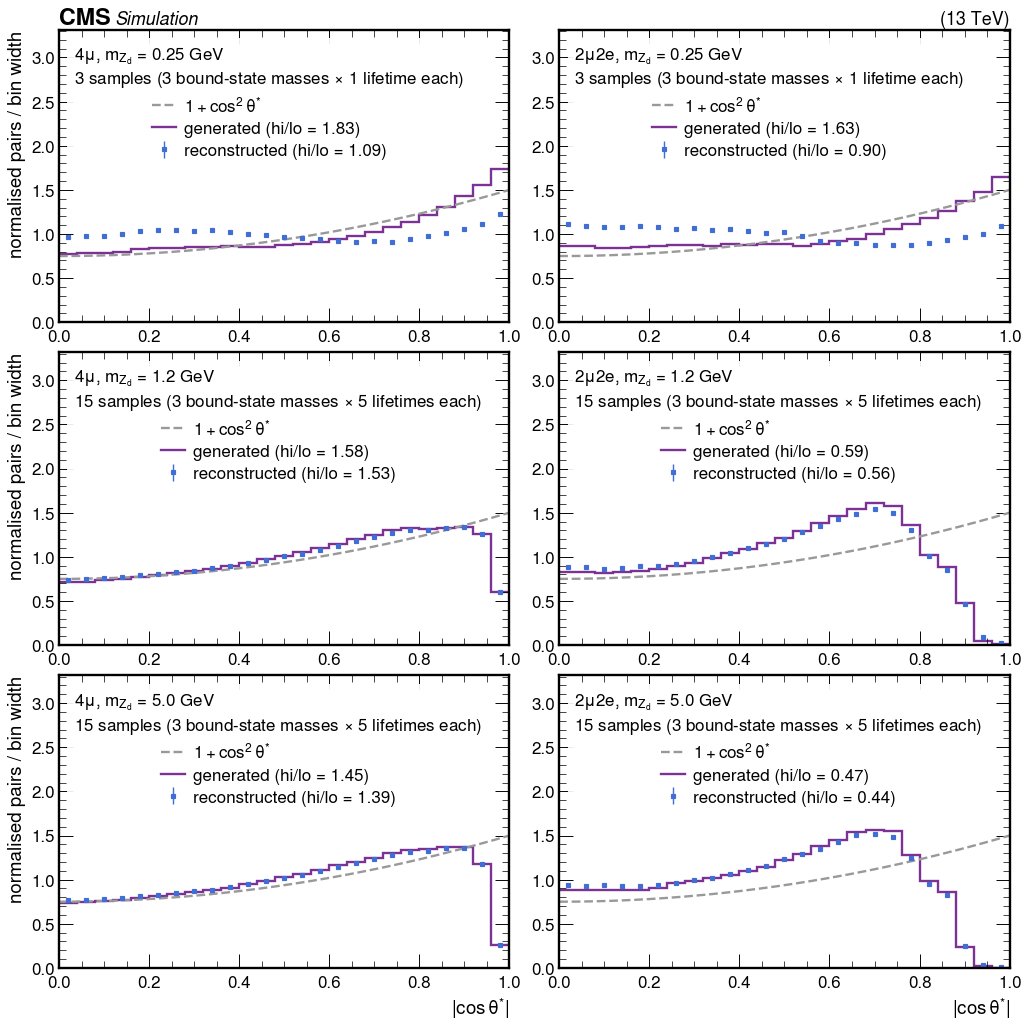

In [7]:
c_gen_reco = lib.fig_gen_vs_reco(m_zd_values=M_ZD_VALUES)

  wrote sidm/studies/mulj_decay_angle/figures/b2_ridge_map.pdf
  reconstructed column means against the band, 25 columns with at least 20 pairs:
    median deviation 0.6%, 23 of 25 columns within 4%
    worst column |cos theta*| = 0.98: measured 0.024 against 0.018, +34%


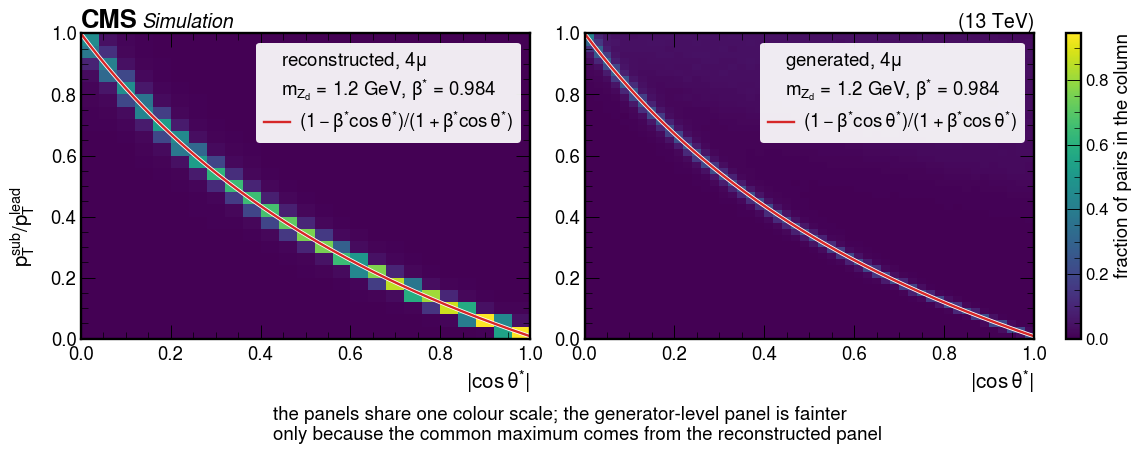

In [8]:
c_ridge = lib.fig_ridge_map(m_zd=M_ZD_REFERENCE)

How to read these figures: the first overlays the generated and
the reconstructed angle, one row per dark-photon mass and one column per final state; the second
shows the reconstructed pairs on the left and the generator-level truth on the right, with the
three bound-state masses m_XX summed, and the dashed curve is the analytic band r =
(1 - beta* cos theta*)/(1 + beta* cos theta*) evaluated at the sample dimuon mass. The
reconstructed pairs track the analytic ridge bin for bin; the printed line under the figure
gives the agreement (median column deviation 0.6 percent, 23 of 25 columns within 4 percent,
the worst column at the sparse |cos(theta*)| = 0.98 edge).

At m_Zd = 1.2 and 5.0 GeV reconstruction changes the angle little: the hi/lo ratio (density
above 0.8 over density below 0.2) moves from 1.58 generated to 1.53 reconstructed at 1.2 GeV in
the 4mu channel, and by three to seven percent elsewhere. The generated curves at these two
masses are a sound reference: the precision check below reproduces the generated angle to about
one percent of alpha at every bound-state mass.

At m_Zd = 0.25 GeV the generated curve is not a sound reference, and the hi/lo it prints (1.83 in
4mu, 1.63 in 2mu2e) does not describe the decay. The generated histogram boosts each muon into
its dark photon's rest frame in single precision. A 0.25 GeV dark photon from a 500 or 1000 GeV
bound state has a Lorentz factor of 1,000 to 2,000, so 1 - beta^2 of the dark photon, 1e-6 to
3e-7, is only a few times the single-precision resolution of 6e-8, and the boost misplaces the
muon, more often towards |cos(theta*)| = 1. The expectation is alpha = 0.17 for beta* = 0.53, a
hi/lo of 1.13: the decay is nearly flat.

A reading of the angle that needs no boost,
|cos(theta*)| = |E1 - E2| / (beta* |p1 + p2|), confirms it in an offline check of one file
(check_gen_boost_precision.py in this directory), the 4mu sample with m_XX = 500 GeV,
m_Zd = 0.25 GeV and c tau = 0.004 mm (its file part-0, no selection, 16,674 dark photons with
two muons): alpha = 0.14 +- 0.03 with beta* taken from each dark photon's generated mass (0.19
expected for that mass distribution), while the processor's single-precision boost gives
0.51 +- 0.04 on the same muons and the same boost in double precision 0.15 +- 0.03. The
reconstructed hi/lo of 1.09 (4mu) and 0.90 (2mu2e) is close to the decay's 1.13, so the flat
reconstructed shape does not indicate a loss in reconstruction. It is the net of the decay, the
same single-precision boost applied to the stored muons, the detector resolution and the
acceptance, which this study does not separate; the table below gives what the arithmetic alone
does at truth level.

The overflow of the |cos(theta*)| axis holds the entries the arithmetic places outside it
(caveat 9): a few in a hundred thousand in data and at most 0.2 percent of the simulated entries
at m_Zd = 1.2 and 5.0 GeV, but 2 to 18 percent at m_Zd = 0.25 GeV with m_XX = 500 and
1000 GeV, as the table at the end of this section counts from the stored histograms.  Every
figure is built from the in-range bins.

### What the stored precision and the arithmetic can resolve

The generator record keeps GenPart pt, eta, phi and mass at 8 mantissa bits, a step of 0.4 to 0.8
percent of each value; for eta and phi of order one that is several times the 8e-4 rad median
opening angle between the two muons of a 0.25 GeV dark photon at m_XX = 500 GeV.  The generated
histograms do not use those branches: coffea builds the generator-level momenta from the px, py
and pz branches, which are stored in full single precision, and only the dark photon's mass is
read at 8 bits.  The reconstructed muons keep pt in full single precision and eta and phi at 12
mantissa bits, a step of up to 5e-4 rad for the values that occur.  Every boost is computed in
single precision.

The toy below generates XX -> Zd Zd -> 4 mu decays with the angular distributions of the model,
stores them at these precisions, and recomputes both angles with the processor's own functions.
The two angles are |cos(theta*)|, whose shape coefficient is alpha, and the azimuthal angle Phi
between the two dark photons' decay planes, whose coefficient A is defined in section j.  The
toy's docstring gives the kinematics.  There is no generator filter, no selection and no detector
resolution.  It reads no files and runs in about twenty seconds.

In [9]:
toy_rows = lib.storage_precision_toy()

200000 toy events per point, XX rapidity uniform in +-1.0, both dark photons in |eta| < 2.4; opening: median angle between the two muons [rad]

|cos theta*|: alpha of 1 + alpha cos^2 theta* fitted to 25 bins, hi/lo as in section b, >0.96: fraction above 0.96
                          |                        |       as the generated histograms        | reconstructed precision
m_XX/m_Zd  gamma  opening | alpha in         exact |         alpha hi/lo >0.96        energy |         alpha hi/lo
-----------------------------------------------------------------------------------------------------------------
  100/0.25    213  4.2e-03 |    0.167 +0.167+-0.006 | +0.169+-0.006  1.13 0.044 +0.167+-0.006 | +0.166+-0.006  1.13
  500/0.25   1066  8.4e-04 |    0.167 +0.164+-0.006 | +0.305+-0.007  1.23 0.049 +0.164+-0.006 | +0.247+-0.006  1.17
 1000/0.25   2133  4.2e-04 |    0.167 +0.177+-0.006 | +1.719+-0.014  2.33 0.087 +0.177+-0.006 | +2.473+-0.019  2.89
  100/1.2      44  5.5e-02 |    0.940 +0.943

How to read this table: "exact" recomputes the angles in double
precision from the toy's four-vectors and recovers the input alpha and A at every point within two
standard deviations, which checks the toy and the fit.  "As the generated histograms" applies the
processor's functions to the generator record as coffea reads it.  At m_Zd = 1.2 and 5.0 GeV it
agrees with "exact" for both angles, within 0.011 in alpha (at m_XX = 1000 GeV, m_Zd = 1.2 GeV)
and exactly in A, so the generated references of sections b and j are sound there and the
reconstructed-over-generated ratios of section j need no correction.  At m_Zd = 0.25 GeV the
plane angle is unaffected, A_out = A_in, but |cos(theta*)| is not: alpha comes out 0.17 at
m_XX = 100 GeV (a Lorentz factor of about 200), 0.31 at 500 GeV and 1.7 at 1000 GeV against an
input of 0.17.  The boost-free "energy" reading stays at the input everywhere.

The toy does not reproduce the real file exactly.  In the offline check of one file
(check_gen_boost_precision.py in this directory) at m_XX = 500 GeV, m_Zd = 0.25 GeV the processor
gives alpha = 0.51 +- 0.04 and hi/lo 1.41 where the toy gives 0.31 and 1.23, and on the
corresponding m_XX = 1000 GeV file 2.2 against 1.7.  The toy uses a fixed m_Zd, while the
generated dark-photon mass has a broad lineshape (dimuon mass 0.226 to 0.366 GeV, 1 to 99
percent, on the checked file), and its spectrum of dark-photon energies is not the generator's
(median Lorentz factor 1,171 in the file against 1,066 in the toy at m_XX = 500 GeV); the
distortion grows steeply with the Lorentz factor.  The toy is not tuned to close the gap, so it
sizes the effect and does not correct the stored histograms, which cannot be refilled without
rerunning the campaign.  The stored generated histogram of the 4mu channel at m_XX = 500 GeV,
m_Zd = 0.25 GeV reads hi/lo 1.46 (table below), in line with the 1.41 of the unselected file.

"Reconstructed precision" is the reconstruction construction at truth level (each pair the sum
of its two stored muons, the angle that of the leading muon), with no detector resolution.  At
m_Zd = 0.25 GeV it is distorted as well (alpha 0.25 at m_XX = 500 GeV, 2.5 at 1000 GeV), so the
reconstructed angle at that mass carries the arithmetic on top of the detector resolution; at 1.2
and 5.0 GeV it equals the exact value, and the reconstructed plane angle keeps A to better than
one percent at those masses.  The last two columns of the Phi table give the correlation r of the
two signed helicity angles of section j, exact and as the generated histograms compute it.

The table below counts the overflow entries quoted above and in caveat 9 from the stored
histograms, flow bins included: in the data only in the uncut single-lepton-jet control region,
and in simulation in the inclusive channel of each mass point, all lifetimes summed.

In [10]:
overflow_rows = lib.overflow_table()

overflow of the stored histograms, raw entries, flow bins included
2018 data, uncut single-lepton-jet control region: |cos theta*| 333 of 8,242,639 (4.0e-05); momentum ratio 1 of 8,242,639
  dimuon mass of those |cos theta*| overflow entries: 272 below 0.2 GeV (negative masses included), 61 from 0.2 to 0.8 GeV, 0 above 0.8 GeV

signal, inclusive channel, all lifetimes summed: overflow fraction of the reconstructed and generated |cos theta*|, generated hi/lo from the in-range bins
final state  m_XX/m_Zd | reconstructed    entries |  generated    entries | gen hi/lo
----------------------------------------------------------------------------------
        4mu   100/0.25 |        0.0000     79,982 |     0.0000    156,020 |      2.31
        4mu   500/0.25 |        0.0395    478,865 |     0.0434    933,858 |      1.46
        4mu  1000/0.25 |        0.1248    312,922 |     0.1776    609,898 |      2.54
        4mu   100/1.2  |        0.0000    200,107 |     0.0000    320,094 |      0.14
  

        4mu   500/5.0  |        0.0000  1,155,278 |     0.0000  1,526,782 |      1.32
        4mu  1000/5.0  |        0.0001    901,935 |     0.0000  1,189,956 |      1.83
      2mu2e   100/0.25 |        0.0005      2,031 |     0.0000      3,978 |      0.03


      2mu2e   500/0.25 |        0.0231    109,003 |     0.0254    212,716 |      1.38
      2mu2e  1000/0.25 |        0.0698     52,810 |     0.1099    102,888 |      2.73
      2mu2e   100/1.2  |        0.0000      2,882 |     0.0000      4,628 |      0.00
      2mu2e   500/1.2  |        0.0001    227,288 |     0.0000    360,132 |      0.06
      2mu2e  1000/1.2  |        0.0012    173,953 |     0.0000    274,268 |      2.03
      2mu2e   100/5.0  |        0.0000      2,387 |     0.0000      3,280 |      0.00
      2mu2e   500/5.0  |        0.0000    182,675 |     0.0000    241,188 |      0.04
      2mu2e  1000/5.0  |        0.0002    142,165 |     0.0000    186,000 |      1.38


## c. Acceptance

The reconstructed angle in the two signal final states side by side, and where the sub-leading muon
of the pair sits in transverse momentum as a function of the angle.  The dashed lines on the maps
mark the two trigger-relevant thresholds; the top-right panel is the fraction of pairs below each of
them, drawn only where the angle bin holds at least 20 pairs.

The map is drawn on the bin index of the momentum axis, because that axis is variable-binned from
zero and a logarithmic axis would drop its first bin.

  wrote sidm/studies/mulj_decay_angle/figures/c1_acceptance.pdf


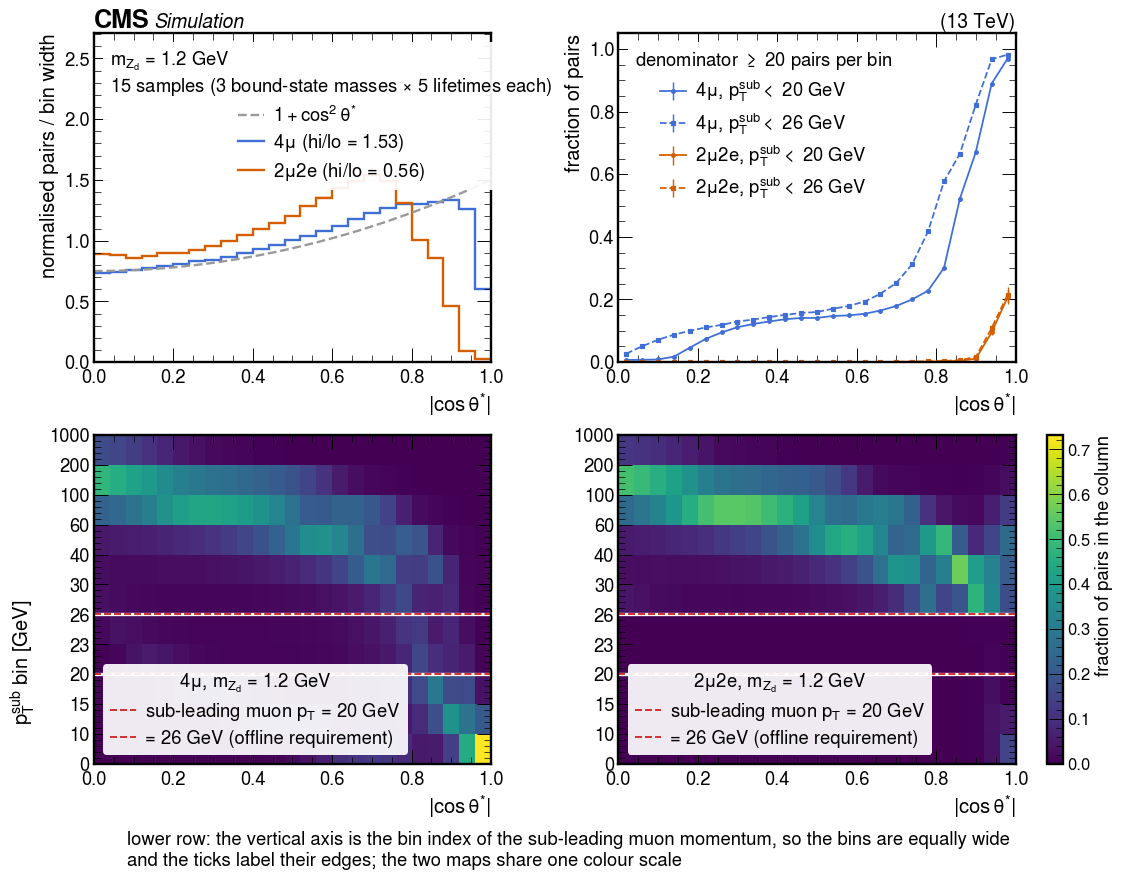

In [11]:
c_acceptance = lib.fig_acceptance(m_zd=M_ZD_REFERENCE)

The reconstructed |cos(theta*)| shape is sculpted by the trigger and muon pT thresholds, and
the sculpting is channel dependent. Large |cos(theta*)| means a hard-soft pair: as
|cos(theta*)| -> 1 the sub-leading muon pT collapses (visible in the maps as the population
crossing below the 20-26 GeV lines). In the 2mu2e channel both level-2 trigger muons (23 or 25
GeV) must come from the single muon lepton jet, and the offline selection then requires two
muons above 26 GeV, so asymmetric pairs fail and the distribution is cut off well before
|cos(theta*)| = 1. In the 4mu channel the two required muons can come from different lepton
jets, and the asymmetric pairs survive even though the fraction of them whose sub-leading muon
falls below the 26 GeV requirement grows to about two thirds by |cos(theta*)| = 0.86. The same
mechanism acts in any selection requiring two muons above 26 GeV from one lepton jet, which is
why the signal shape in the cleaned single-lepton-jet control region below is depleted above
0.8. Consequence: none of the reconstructed shapes here is a polarization measurement; they are
shapes under a fixed selection, compared like for like.

## d. Signal, simulated background and data, region by region

Unit-area shapes so that only the shape is compared: rows are the five regions, columns the
dark-photon mass.  Signal curves sum the three bound-state masses with raw-count weights; the
per-mass table below, for the first row at m_Zd = 1.2 GeV, shows the spread that sum hides.
Simulated backgrounds are combined with their cross-section weights before the shape is taken.  The
observed distribution carries asymmetric Poisson error bars.

Everything in a panel is drawn under the same selection as the data in that panel, which is the
comparison this study is built to make.  Panels with no entries are left empty and labelled.

Note on the two validation-region rows: their inverted-displacement requirement asks each muon lepton
jet for at least one muon with more than two pixel hits, which a displaced-standalone muon never has.
It does not exclude displaced-standalone muons from the pair: 29 percent of the four-muon and 10
percent of the two-muon-two-electron data pairs contain one (table in section a).  The row labels
state the requirement, and caveat 2 below spells it out.

  [note] signal 2mu2e in 4mu inverted-displacement VR, m_Zd = 0.25 GeV, absCosTheta: 34 entries over 5 bins, below the 50 needed to draw a shape at all; not drawn


  high-to-low density ratio of every curve drawn (mean density above 0.8 over mean density below 0.2):
    region                                 | series                 |  m_Zd |          hi/lo
    1 mu-LJ CR (no cleaning)               | signal 4mu             |  0.25 |  0.734 +- 0.029
    1 mu-LJ CR (no cleaning)               | signal 2mu2e           |  0.25 |  0.716 +- 0.022
    1 mu-LJ CR (no cleaning)               | simulated background   |     - |  0.023 +- 0.001
    1 mu-LJ CR (no cleaning)               | data                   |     - |  0.035 +- 0.000
    1 mu-LJ CR (no cleaning)               | signal 4mu             |  1.20 |  1.237 +- 0.009
    1 mu-LJ CR (no cleaning)               | signal 2mu2e           |  1.20 |  0.644 +- 0.008
    1 mu-LJ CR (no cleaning)               | signal 4mu             |  5.00 |  1.157 +- 0.009
    1 mu-LJ CR (no cleaning)               | signal 2mu2e           |  5.00 |  0.658 +- 0.008
    1 mu-LJ CR + cosmic veto               | signal 

  wrote sidm/studies/mulj_decay_angle/figures/d1_region_shapes_absCosTheta.pdf

  signal hi/lo per bound-state mass m_XX, 1 mu-LJ CR (no cleaning), m_Zd = 1.2 GeV:
    final state |   m_XX |     pairs |          hi/lo
    4mu         |    100 |    30,205 |  0.069 +- 0.003
    4mu         |    500 |    97,912 |  1.131 +- 0.012
    4mu         |   1000 |    73,210 |  2.477 +- 0.031
    4mu         | summed |   201,327 |  1.237 +- 0.009
    2mu2e       |    100 |    10,361 |  0.007 +- 0.001
    2mu2e       |    500 |    48,021 |  0.411 +- 0.008
    2mu2e       |   1000 |    30,587 |  2.238 +- 0.046
    2mu2e       | summed |    88,969 |  0.644 +- 0.008


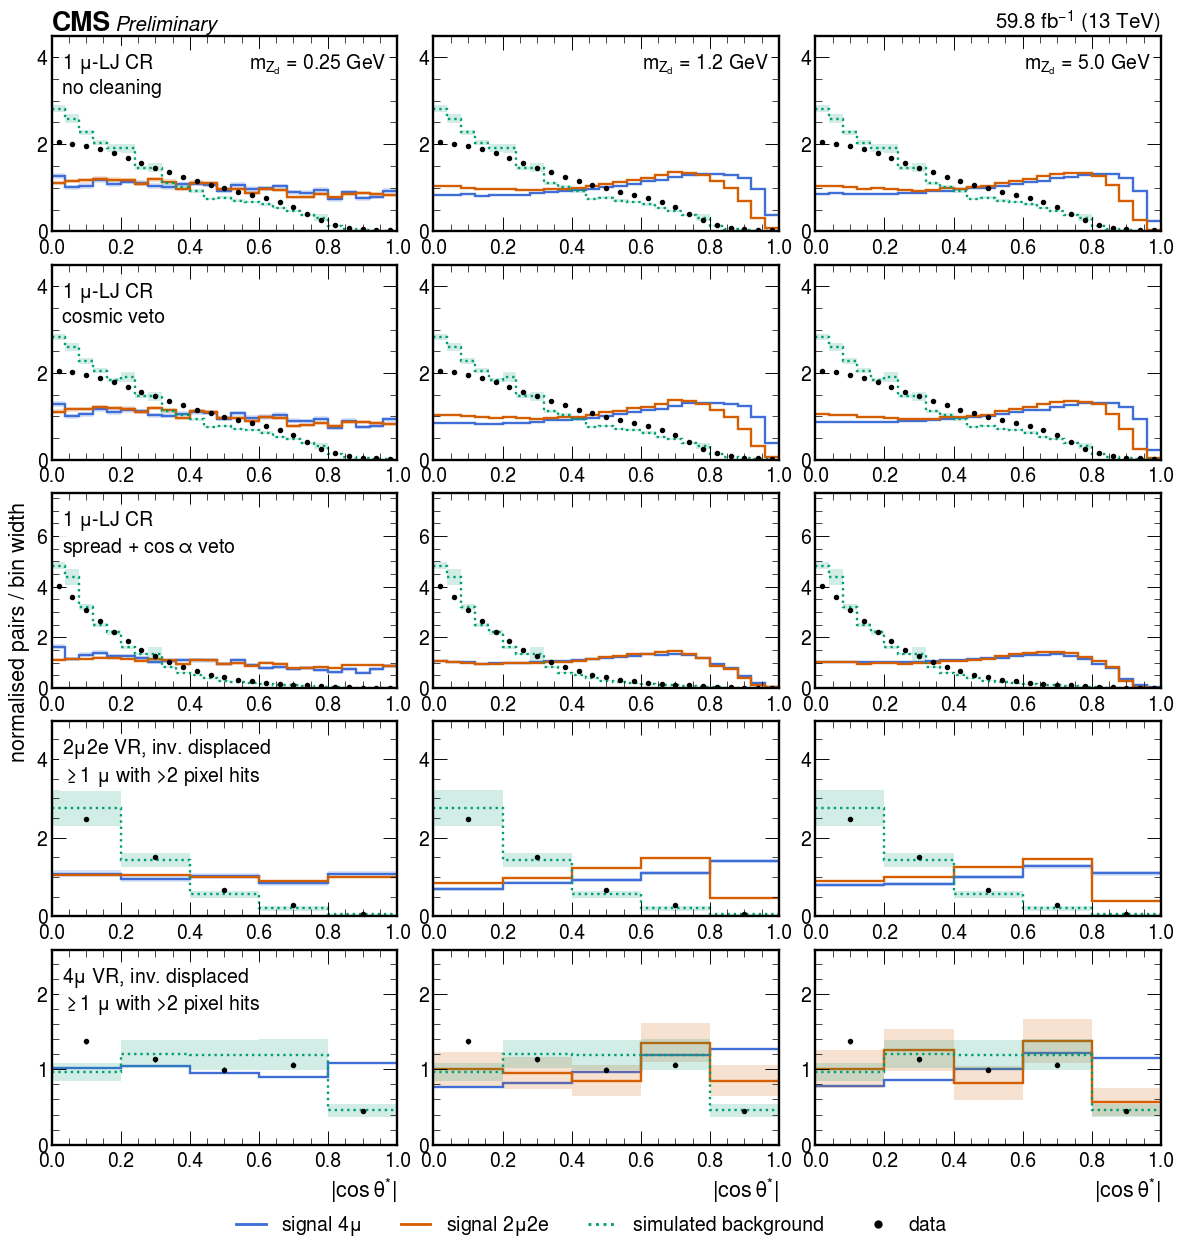

In [12]:
c_shapes_cos = lib.fig_region_shapes("absCosTheta", m_zd_values=M_ZD_VALUES)
print()
_ = lib.signal_hi_lo_by_mass(lib.UNCUT_CR, m_zd=M_ZD_REFERENCE)

  [note] signal 2mu2e in 4mu inverted-displacement VR, m_Zd = 0.25 GeV, ptRatio: 34 entries over 10 bins, below the 50 needed to draw a shape at all; not drawn


  [note] signal 2mu2e in 4mu inverted-displacement VR, m_Zd = 5.0 GeV, ptRatio: 3 of 10 bins hold fewer than 5 effective entries and are not drawn
  high-to-low density ratio of every curve drawn (mean density above 0.8 over mean density below 0.2):
    region                                 | series                 |  m_Zd |          hi/lo
    1 mu-LJ CR (no cleaning)               | signal 4mu             |  0.25 | 14.089 +- 1.451
    1 mu-LJ CR (no cleaning)               | signal 2mu2e           |  0.25 | 14.225 +- 1.163
    1 mu-LJ CR (no cleaning)               | simulated background   |     - |  5.756 +- 0.200
    1 mu-LJ CR (no cleaning)               | data                   |     - |  4.289 +- 0.007
    1 mu-LJ CR (no cleaning)               | signal 4mu             |  1.20 |  0.263 +- 0.002
    1 mu-LJ CR (no cleaning)               | signal 2mu2e           |  1.20 |  0.399 +- 0.005
    1 mu-LJ CR (no cleaning)               | signal 4mu             |  5.00 |  0.269 +- 0.002

  wrote sidm/studies/mulj_decay_angle/figures/d1_region_shapes_ptRatio.pdf


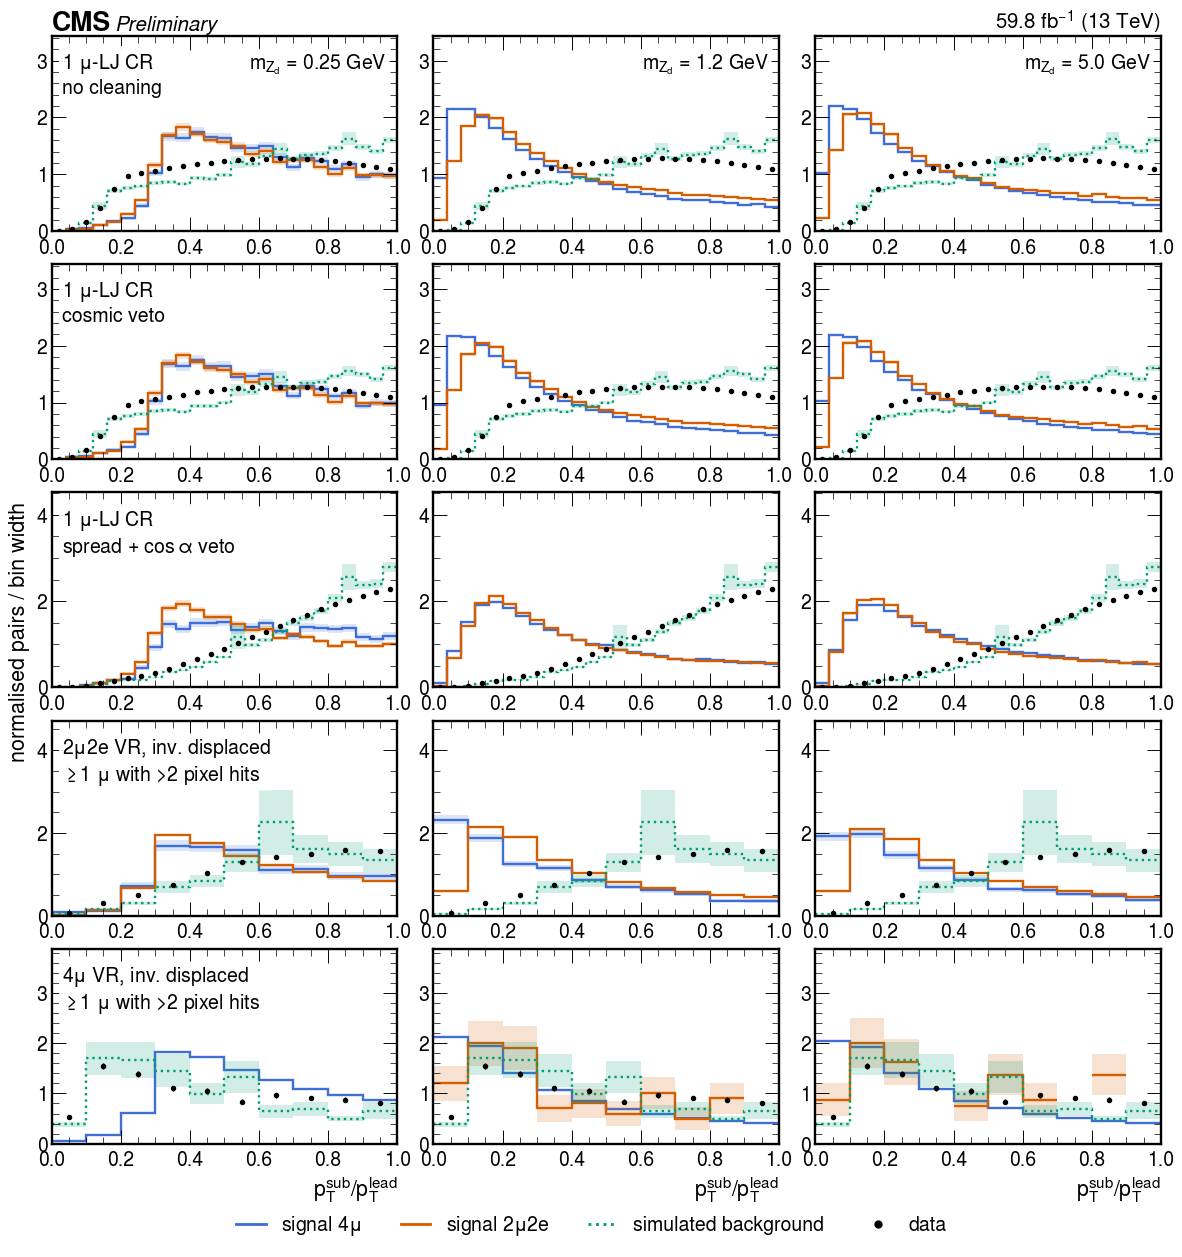

In [13]:
c_shapes_ratio = lib.fig_region_shapes("ptRatio", m_zd_values=M_ZD_VALUES)

How to read this figure: each row is one region, each column one dark-photon mass, every
curve is normalized to unit area, and the question is whether the fake-dominated data shape
differs from the signal shape under the same selection. The signal curves sum the three
bound-state masses m_XX = 100, 500 and 1000 GeV with raw-count weights; the first printed
table under the figure gives every curve's hi/lo ratio, and the second splits the signal of
the uncut single-lepton-jet control region (the first row) at m_Zd = 1.2 GeV by bound-state
mass. The spread across m_XX is large: there the 4mu hi/lo is 0.069 at m_XX = 100 GeV, 1.131
at 500 GeV and 2.477 at 1000 GeV (2mu2e: 0.007, 0.411 and 2.238), because heavier bound states
make harder lepton jets whose asymmetric pairs survive the thresholds. The data shape falls
steeply with |cos(theta*)| in the single-lepton-jet control regions and in the two-muon-two-electron
validation region (hi/lo 0.008 to 0.035) and only mildly in the four-muon validation region
(0.33). The signal curves as
drawn give hi/lo 1.24 and 1.16 in 4mu at m_Zd = 1.2 and 5.0 GeV; in 2mu2e they give 0.64
and 0.66, the tail above 0.8 removed by acceptance, with the separation from data living in
the middle of the axis, 0.4 < |cos(theta*)| < 0.8.

Three qualifications.  First, at
m_Zd = 0.25 GeV the signal column is nearly flat (hi/lo 0.73 and 0.72 as drawn), as the decay
itself is, 1 + 0.17 cos^2(theta*) (section b). Against the steeply falling single-lepton-jet
fakes a flat shape still separates: signal efficiency over the square root of the fake
efficiency for a cut at 0.4 is 1.6 to 1.7 against the cleaned single-lepton-jet control region
(section j), comparable to the 1.6 to 2.1 at the heavier masses. The reconstructed angle at this
mass carries the single-precision arithmetic of section b (4 to 12 percent of the four-muon
entries fall in the overflow at m_XX = 500 and 1000 GeV), so these numbers describe the variable
as computed, and it should be recomputed in double precision before it is used at this mass
point. Second, in regions that require two 26 GeV muons from the single
jet, the signal tail above 0.8 is removed by acceptance (previous section) and only the mid-axis
separation remains. Third, the weighted background simulation in the validation-region rows
rests on a few hundred effective entries dominated by a handful of high-weight QCD events;
it is shown for completeness, and the comparison is made with the data.

## e. What the angle correlates with

If the shape of the angle in a control region is to be carried into the signal region, it must not
depend on the quantities that separate the two.  Each panel below takes one companion quantity,
slices the data in it, and overlays the unit-area angular distribution of each slice; a change of
shape between the curves of one panel is a correlation.  The companions are split over two
figures each, four panels apiece, so that every panel is wide enough to read at the width the
figure is placed at.  The profile figures show the same
information as one number per companion bin, the mean angle, with the standard error of the mean and
only where the bin holds at least 20 pairs.

The measurement is made in the uncut single-lepton-jet control region, which is the only region that
contains pairs across the whole range of displacement, and the one with the most pairs containing
displaced-standalone muons in number.  The same set is repeated
for signal, where the angle is a property of a real decay.

  wrote sidm/studies/mulj_decay_angle/figures/e1a_correlation_overlays_data_displacement.pdf
  pairs behind each slice of 2018 data, uncut single-lepton-jet control region: isolation and impact parameters:
    mu-LJ isolation  |      < 0.1 |    1,169,495
    mu-LJ isolation  |    0.1-0.3 |    1,906,041
    mu-LJ isolation  |      0.3-1 |    3,830,033
    mu-LJ isolation  |       1-10 |    1,329,597
    min |d_xy| [cm]  |     < 0.02 |    7,021,780
    min |d_xy| [cm]  |   0.02-0.1 |    1,067,648
    min |d_xy| [cm]  |      0.1-1 |       88,770
    min |d_xy| [cm]  |     1-1000 |       64,441
    max |d_xy| [cm]  |     < 0.02 |    4,864,575
    max |d_xy| [cm]  |   0.02-0.1 |    2,241,925
    max |d_xy| [cm]  |      0.1-1 |      564,132
    max |d_xy| [cm]  |     1-1000 |      572,007
    d_xy spread [cm] |      < 0.1 |    6,788,994
    d_xy spread [cm] |      0.1-1 |      825,352
    d_xy spread [cm] |       1-10 |      435,124
    d_xy spread [cm] |    10-1000 |      193,153


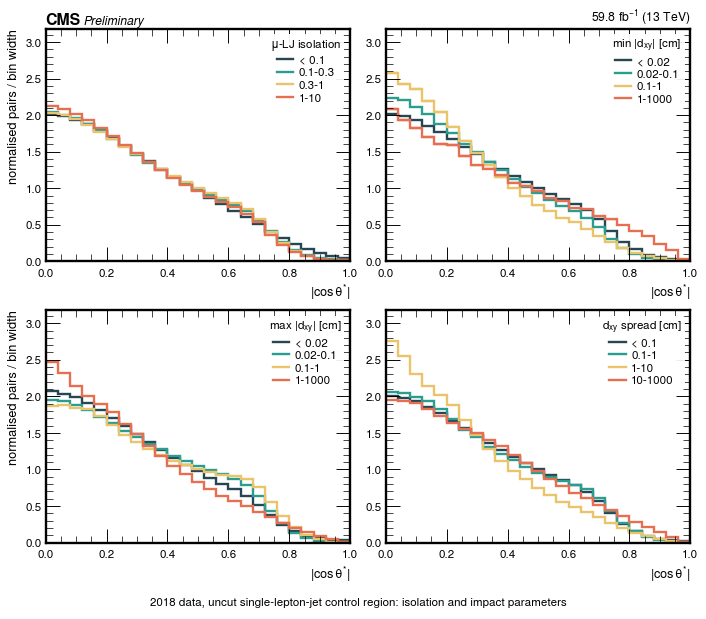

In [14]:
c_corr_data_d = lib.fig_correlation_overlays(
    lib.data_samples(), lib.UNCUT_CR,
    "2018 data, uncut single-lepton-jet control region: isolation and impact parameters",
    "e1a_correlation_overlays_data_displacement", is_data=True,
    companions=lib.companion_group("displacement"))

  wrote sidm/studies/mulj_decay_angle/figures/e1b_correlation_overlays_data_kinematics.pdf
  pairs behind each slice of 2018 data, uncut single-lepton-jet control region: kinematics and muon type:
    mu-LJ p_T [GeV]   |       < 50 |    4,107,723
    mu-LJ p_T [GeV]   |     50-100 |    3,616,965
    mu-LJ p_T [GeV]   |    100-200 |      471,886
    mu-LJ p_T [GeV]   |   200-1000 |       45,567
    m_mumu [GeV]      |        < 1 |    1,625,851
    m_mumu [GeV]      |        1-2 |    1,930,079
    m_mumu [GeV]      |        2-6 |    4,109,134
    m_mumu [GeV]      |      6-200 |      577,352
    DSA muons in pair |  0 (PF-PF) |    7,639,850
    DSA muons in pair | 1 (PF-DSA) |      536,349
    DSA muons in pair | 2 (DSA-DSA) |       66,440
    d_z spread [cm]   |      < 0.1 |    6,105,197
    d_z spread [cm]   |      0.1-1 |    1,224,552
    d_z spread [cm]   |       1-10 |      505,638
    d_z spread [cm]   |    10-1000 |      407,085


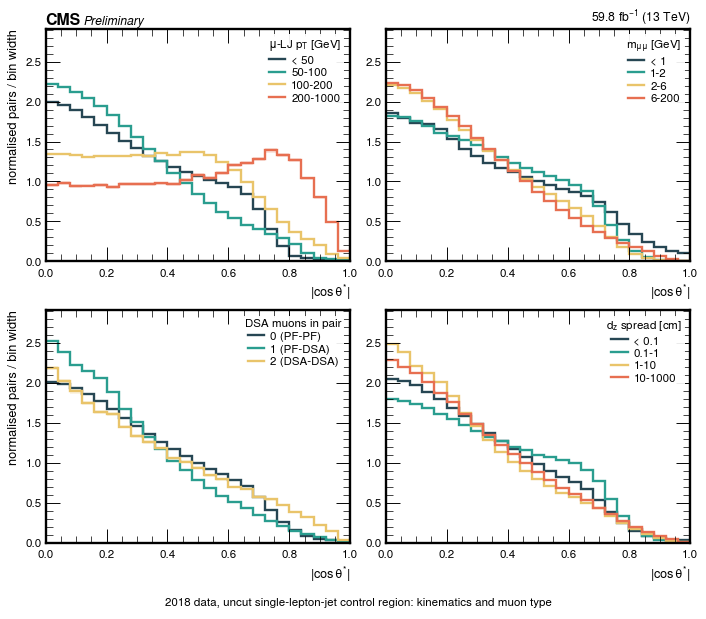

In [15]:
c_corr_data_k = lib.fig_correlation_overlays(
    lib.data_samples(), lib.UNCUT_CR,
    "2018 data, uncut single-lepton-jet control region: kinematics and muon type",
    "e1b_correlation_overlays_data_kinematics", is_data=True,
    companions=lib.companion_group("kinematics"))

  wrote sidm/studies/mulj_decay_angle/figures/e2_correlation_profiles_data.pdf


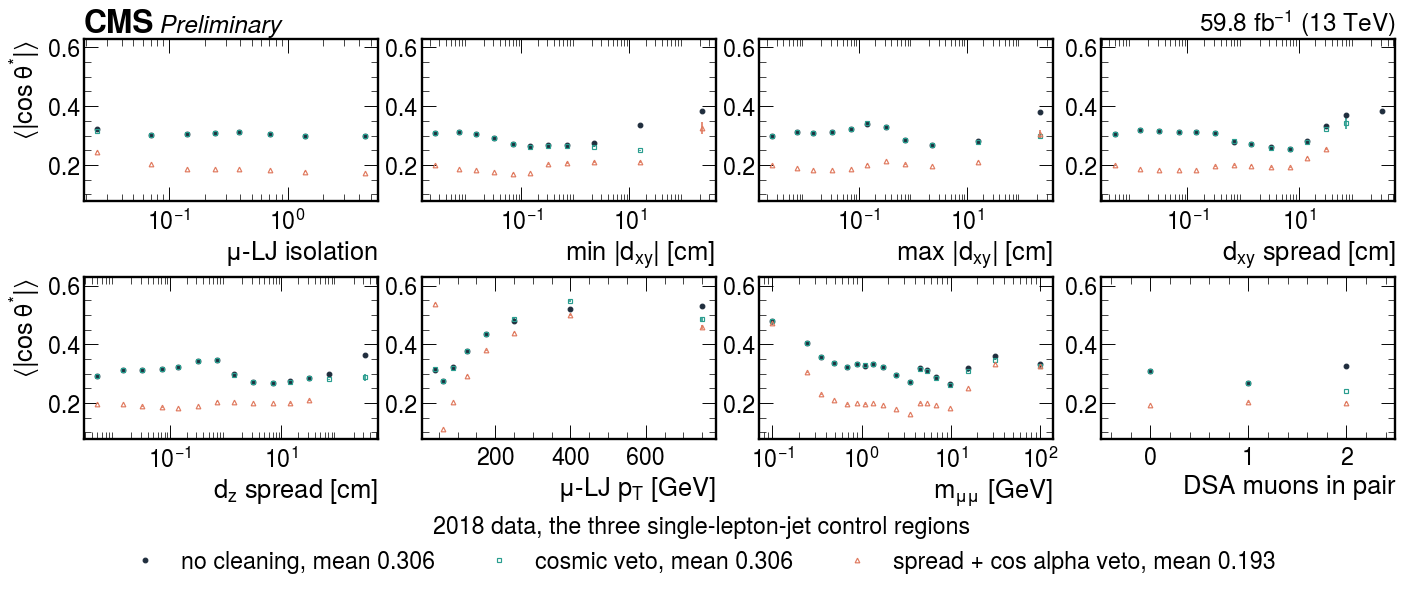

In [16]:
c_prof_data = lib.fig_correlation_profiles(
    lib.data_samples(), lib.UNCUT_CR,
    "2018 data, the three single-lepton-jet control regions",
    "e2_correlation_profiles_data", is_data=True,
    regions=lib.PROFILE_REGIONS)

  wrote sidm/studies/mulj_decay_angle/figures/e3a_correlation_overlays_signal_displacement.pdf
  pairs behind each slice of signal 4mu, m_Z_d = 1.2 GeV, four-muon channel: isolation and impact parameters:
    mu-LJ isolation  |      < 0.1 |    2,123,001
    mu-LJ isolation  |    0.1-0.3 |      125,875
    mu-LJ isolation  |      0.3-1 |       18,073
    mu-LJ isolation  |       1-10 |        2,363
    min |d_xy| [cm]  |     < 0.02 |    1,805,674
    min |d_xy| [cm]  |   0.02-0.1 |      263,038
    min |d_xy| [cm]  |      0.1-1 |      167,447
    min |d_xy| [cm]  |     1-1000 |       38,849
    max |d_xy| [cm]  |     < 0.02 |    1,344,663
    max |d_xy| [cm]  |   0.02-0.1 |      401,909
    max |d_xy| [cm]  |      0.1-1 |      293,150
    max |d_xy| [cm]  |     1-1000 |      235,286
    d_xy spread [cm] |      < 0.1 |    1,699,814
    d_xy spread [cm] |      0.1-1 |      322,654
    d_xy spread [cm] |       1-10 |      213,368
    d_xy spread [cm] |    10-1000 |       39,172


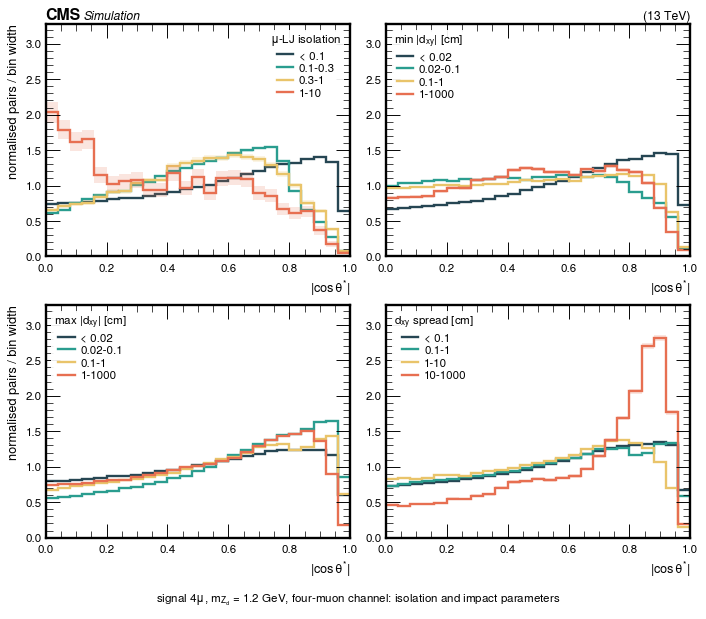

In [17]:
c_corr_sig_d = lib.fig_correlation_overlays(
    lib.signal_samples("4Mu", m_zd=M_ZD_REFERENCE), "4mu",
    f"signal $4\\mu$, $m_{{Z_d}}$ = {M_ZD_REFERENCE} GeV, four-muon channel: "
    "isolation and impact parameters",
    "e3a_correlation_overlays_signal_displacement",
    companions=lib.companion_group("displacement"))

  wrote sidm/studies/mulj_decay_angle/figures/e3b_correlation_overlays_signal_kinematics.pdf
  pairs behind each slice of signal 4mu, m_Z_d = 1.2 GeV, four-muon channel: kinematics and muon type:
    mu-LJ p_T [GeV]   |       < 50 |      128,986
    mu-LJ p_T [GeV]   |     50-100 |      124,211
    mu-LJ p_T [GeV]   |    100-200 |      455,290
    mu-LJ p_T [GeV]   |   200-1000 |    1,564,532
    m_mumu [GeV]      |        < 1 |      179,315
    m_mumu [GeV]      |        1-2 |    1,830,582
    m_mumu [GeV]      |        2-6 |      206,431
    m_mumu [GeV]      |      6-200 |       57,257
    DSA muons in pair |  0 (PF-PF) |    1,925,172
    DSA muons in pair | 1 (PF-DSA) |      264,196
    DSA muons in pair | 2 (DSA-DSA) |       85,640
    d_z spread [cm]   |      < 0.1 |    1,560,401
    d_z spread [cm]   |      0.1-1 |      342,119
    d_z spread [cm]   |       1-10 |      279,465
    d_z spread [cm]   |    10-1000 |       93,023


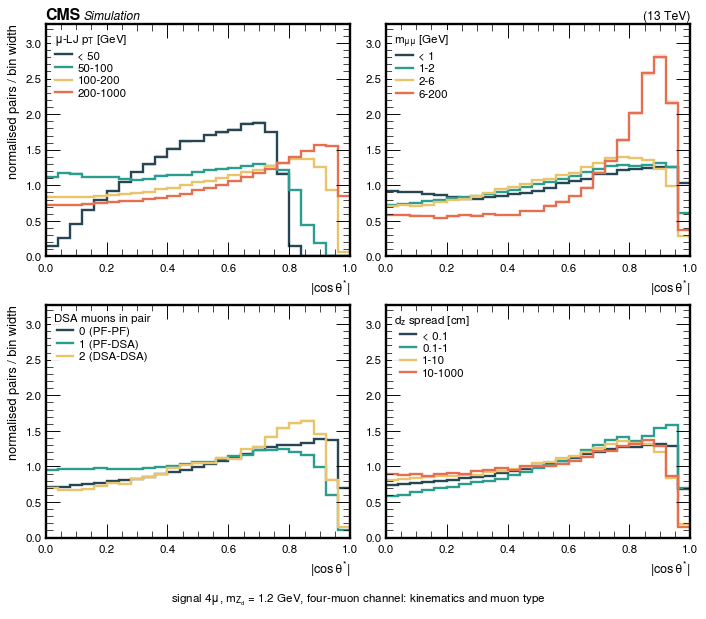

In [18]:
c_corr_sig_k = lib.fig_correlation_overlays(
    lib.signal_samples("4Mu", m_zd=M_ZD_REFERENCE), "4mu",
    f"signal $4\\mu$, $m_{{Z_d}}$ = {M_ZD_REFERENCE} GeV, four-muon channel: "
    "kinematics and muon type",
    "e3b_correlation_overlays_signal_kinematics",
    companions=lib.companion_group("kinematics"))

  wrote sidm/studies/mulj_decay_angle/figures/e4_correlation_profiles_signal.pdf


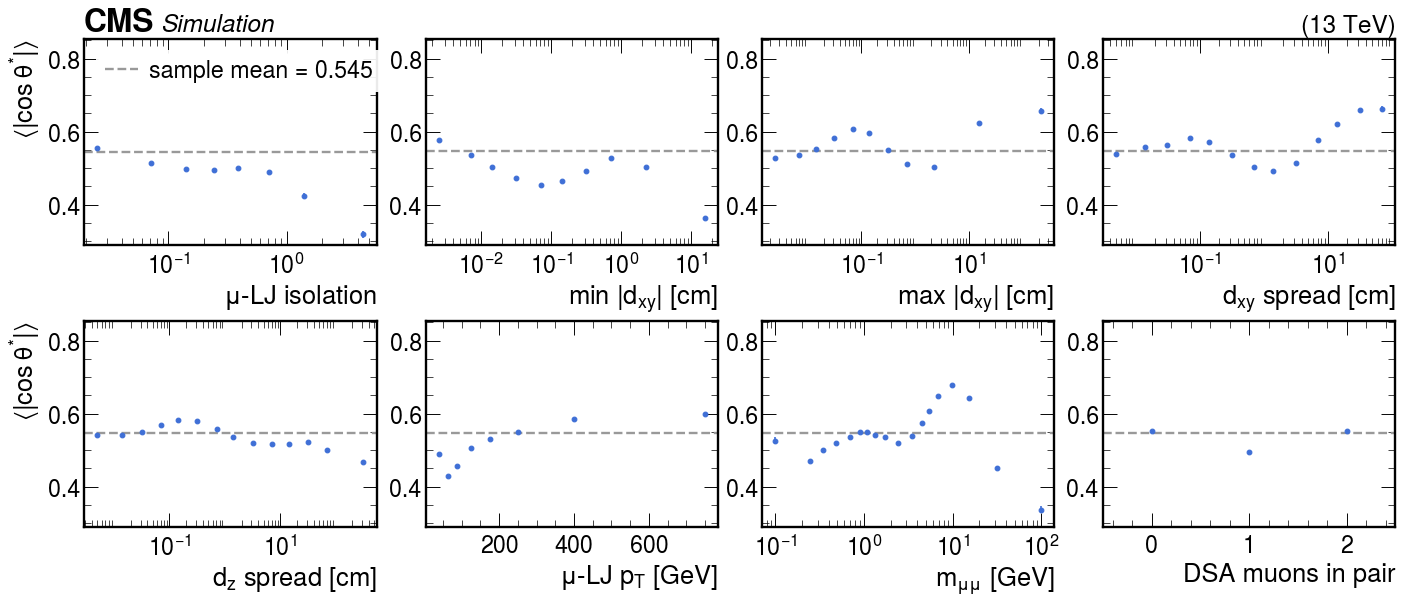

In [19]:
c_prof_sig = lib.fig_correlation_profiles(
    lib.signal_samples("4Mu", m_zd=M_ZD_REFERENCE), "4mu",
    f"signal $4\\mu$, $m_{{Z_d}}$ = {M_ZD_REFERENCE} GeV, four-muon channel",
    "e4_correlation_profiles_signal")

How to read these figures: each panel slices the control-region data in one companion variable;
identical normalized shapes across slices (overlays) and a flat profile of the mean (profiles)
would mean the decay angle carries information independent of that companion. The profile
figure overlays the three single-lepton-jet control regions: uncut, with the cosmic veto, and
cleaned by the spread cuts and the muon-pair opening-angle (cos alpha) veto.  Against lepton-jet
pT the mean rises in every region (Spearman rank correlation +0.98, +0.95, +0.31; from 0.31 at
40 GeV to 0.53 at 750 GeV in the uncut region): harder jets keep their asymmetric pairs, the
acceptance mechanism again. Against isolation the dependence is a moderate fall (mean 0.322 to
0.300 uncut; steeper, -0.93 in rank, after the spread cleaning). Against displacement the
answer depends on the cleaning, and that dependence is itself the finding. In the uncut region
the profile of the mean against the smaller |dxy| of the pair dips by about 13 percent below
one centimeter and then rises to 24 percent above its inner value in the outer bins; after the
cosmic veto the same profile falls by 20 percent (rank correlation -0.92, the visible
difference confined to the outermost bins), because the outer displacement bins of the uncut
region are dominated by the cosmic-ray population the veto removes, together with its |dxy| <=
40 cm requirement on the displaced-standalone muons; after the spread and opening-angle cleaning it
rises again (+63 percent, rank +0.68) on a much smaller residual sample. The size and even the
sign of the displacement dependence change with the cleaning applied, that is, with the
composition of the surviving fakes. The decay angle is therefore not measured to be independent
of displacement, and nothing in this study demonstrates that a fake shape measured in the
inverted-displacement regions transfers across the displacement axis. Any use of the variable in
a background estimate has to measure that dependence in the estimate's own regions.

## f. What a straight cut on the angle would buy

Solid curves are the fraction of signal pairs a threshold keeps, measured in the signal channel of
each final state; dashed curves are the fraction of control-region pairs it rejects.  Bands are
Clopper-Pearson intervals.  Both directions of the cut are shown.

Signal efficiency and fake rejection are measured under different selections (signal in its own
channel, fakes in the data control region), so the two curves in a panel answer "what would this
threshold do here", not "what would it do to the same sample".

The signal curves sum the three bound-state masses with raw-count weights; the per-mass table below
shows the spread that sum hides.  The figure draws only the two single-lepton-jet control regions
as fakes, so the two validation regions are tabulated under it as well.

  wrote sidm/studies/mulj_decay_angle/figures/f1_cut_scan.pdf


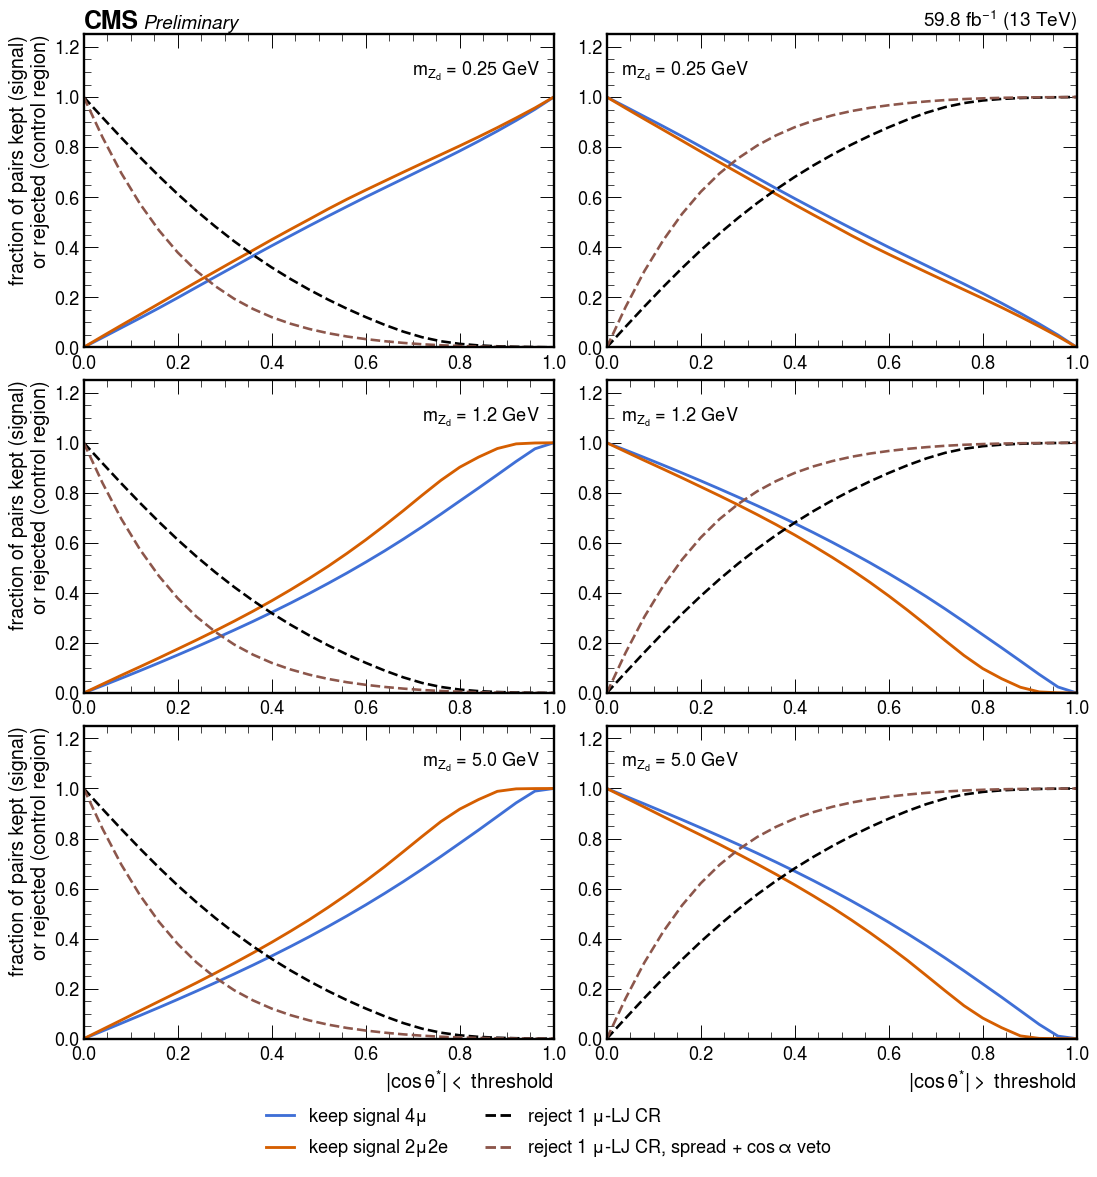

In [20]:
scan = lib.cut_scan(m_zd_values=M_ZD_VALUES)
c_scan = lib.fig_cut_scan(scan, m_zd_values=M_ZD_VALUES)

In [21]:
_ = lib.efficiency_by_mediator_mass(m_zd_values=M_ZD_VALUES)
print()
_ = lib.validation_region_rejection()

  signal pairs kept by |cos theta*| > threshold, one row per bound-state mass m_XX:
    channel |  m_Zd |   m_XX |     pairs |    0.20 |    0.40 |    0.60 |    0.80
    ----------------------------------------------------------------------------
    4mu     |  0.25 |    100 |    79,982 |   0.872 |   0.685 |   0.469 |   0.236
    4mu     |  0.25 |    500 |   459,948 |   0.787 |   0.573 |   0.380 |   0.200
    4mu     |  0.25 |   1000 |   273,877 |   0.807 |   0.604 |   0.412 |   0.235
    4mu     |  1.20 |    100 |   200,107 |   0.857 |   0.627 |   0.330 |   0.020
    4mu     |  1.20 |    500 | 1,224,706 |   0.838 |   0.665 |   0.466 |   0.225
    4mu     |  1.20 |   1000 |   848,041 |   0.860 |   0.708 |   0.528 |   0.294


    4mu     |  5.00 |    100 |   135,728 |   0.845 |   0.609 |   0.308 |   0.019
    4mu     |  5.00 |    500 | 1,155,250 |   0.836 |   0.660 |   0.456 |   0.209
    4mu     |  5.00 |   1000 |   901,842 |   0.851 |   0.690 |   0.500 |   0.262
    2mu2e   |  0.25 |    100 |     2,030 |   0.342 |   0.116 |   0.038 |   0.011
    2mu2e   |  0.25 |    500 |   106,484 |   0.778 |   0.563 |   0.367 |   0.189
    2mu2e   |  0.25 |   1000 |    49,124 |   0.808 |   0.603 |   0.396 |   0.217
    2mu2e   |  1.20 |    100 |     2,882 |   0.203 |   0.053 |   0.015 |   0.001
    2mu2e   |  1.20 |    500 |   227,259 |   0.786 |   0.553 |   0.281 |   0.016
    2mu2e   |  1.20 |   1000 |   173,752 |   0.885 |   0.743 |   0.534 |   0.206
    2mu2e   |  5.00 |    100 |     2,387 |   0.210 |   0.051 |   0.012 |   0.000
    2mu2e   |  5.00 |    500 |   182,668 |   0.788 |   0.558 |   0.281 |   0.009
    2mu2e   |  5.00 |   1000 |   142,138 |   0.858 |   0.697 |   0.489 |   0.178

  data pairs rejected by |c

    4mu inverted-displacement VR     |    5,039 |   0.274 |   0.500 |   0.698 |   0.910


In [22]:
_ = lib.cut_scan_table(scan, direction="below")
print()
_ = lib.cut_scan_table(scan, direction="above")

  |cos theta*| < threshold
    m_Zd | curve                                  |   cut |               kept | rejected |    pairs
  --------------------------------------------------------------------------------------------------
    0.25 | signal 4mu                             |  0.20 | 0.198 -0.000/+0.000 |    0.802 |   813807
    0.25 | signal 4mu                             |  0.40 | 0.406 -0.001/+0.001 |    0.594 |   813807
    0.25 | signal 4mu                             |  0.60 | 0.600 -0.001/+0.001 |    0.400 |   813807
    0.25 | signal 4mu                             |  0.80 | 0.785 -0.000/+0.000 |    0.215 |   813807
    0.25 | signal 4mu                             |  0.88 | 0.864 -0.000/+0.000 |    0.136 |   813807
    0.25 | signal 2mu2e                           |  0.20 | 0.218 -0.001/+0.001 |    0.782 |   157638
    0.25 | signal 2mu2e                           |  0.40 | 0.430 -0.001/+0.001 |    0.570 |   157638
    0.25 | signal 2mu2e                           |  0.60

How to read this figure: solid curves are the fraction of signal pairs kept by a cut at the
threshold on the x axis, dashed curves the fraction of control-region data pairs rejected; both
directions of the cut are shown because the informative side differs by channel. The curves sum
the three bound-state masses; the printed tables under the figure give the per-mass
efficiencies and the validation-region rejections, and the mass dependence is decisive. A cut
keeping |cos(theta*)| > 0.4 rejects 79.6 percent of the data pairs in the two-muon-two-electron
validation region and 50.0 percent in the four-muon validation region (printed table; the figure
draws two of the single-lepton-jet control regions, where the same cut rejects 68 and 88
percent). The same cut
keeps, in the 2mu2e channel, 55 to 56 percent of signal pairs at m_XX = 500 GeV and 70 to 74
percent at 1000 GeV for the two heavier dark-photon masses, but only 5 percent at m_XX = 100
GeV (and 12 percent at m_Zd = 0.25 GeV there): the lightest bound state makes the softest
lepton jets, exactly the ones whose asymmetric pairs the trigger and the 26 GeV requirement
already remove. In the 4mu channel the efficiency is flatter, 57 to 71 percent across the grid.
These are per-lepton-jet numbers, the signal read in its inclusive 4mu and 2mu2e channels and
the fakes in the uncut and the cleaned single-lepton-jet control regions (figure) and the two
validation regions (printed table), not per-event signal-region predictions; in the 4mu channel
a per-jet cut applies to both muon lepton jets of an event, so the event-level signal cost is
roughly the square of the per-jet efficiency. They size the handle; they do not certify it.

## g. Caveats

These apply to every reading of the figures above.

1. **The reconstructed angle is shaped by the selection.** The high-to-low population ratio printed
   in the legends of the first figures is not the value an unsculpted 1 + cos^2 decay would give, and
   the two-muon-two-electron final state loses the region near an absolute cosine of one, because
   both muons that fire the dimuon trigger have to come from the one muon lepton jet and the
   sub-leading muon of a wide-angle pair falls below the trigger threshold.  The generator-level
   distribution in the same channel shows the same shape at m_Zd = 1.2 and 5.0 GeV, which is how
   the sculpting is identified as acceptance rather than physics; at m_Zd = 0.25 GeV the generated
   histogram is not a sound reference (caveat 9).  This study compares signal and fake shapes
   under an identical selection; it is not a measurement of the decay's angular distribution,
   which would require the efficiency to be corrected for.

2. **The inverted-displacement requirement does not exclude displaced-standalone muons.** In the
   two validation regions and the two-lepton-jet control region every muon lepton jet must contain
   at least one muon with more than two pixel hits.  The processor sets the pixel-hit count of
   a displaced-standalone track to zero, so that muon is a particle-flow muon, but the two leading
   muons the angle is computed from can include displaced-standalone ones.  In data the pairs split
   71, 29 and 0.2 percent into particle-flow, mixed and displaced-standalone pairs in the four-muon
   validation region, 90, 10 and 0.2 percent in the two-muon-two-electron one, 59, 41 and below 0.1
   percent in the two-lepton-jet control region, and 93, 6.5 and 0.8 percent in the uncut
   single-lepton-jet control region (table in section a).  Section e separates pairs by the
   number of displaced-standalone muons in the single-lepton-jet control regions; the table in
   section a gives the fraction above 0.4 for each class in every region.

3. **Impact parameters do not all share a reference.** The angle helper uses primary-vertex
   referenced transverse and longitudinal impact parameters for both muon types.  The lepton-jet
   spread quantities used by the cleaning cuts, which are kept exactly as the cuts define them, mix
   primary-vertex referenced particle-flow values with beamspot referenced displaced-standalone
   values; for a mixed pair the transverse spread is close to the displaced-standalone muon's own
   impact parameter rather than a separation between two vertices.  Do not describe it as a vertex
   separation, and slice by the number of displaced-standalone muons where the distinction matters.

4. **These are the as-run definitions, not main's.** Every channel here is defined by
   `selections_mulj_decay_angle_as_run.yaml`.  Main's channels of the same names add an eta-phi
   veto, the `DT + CSC hits > 3` requirement on the muons at the lepton-jet source, and the
   base-cut and spread-cut differences listed under "Selections used in this study",
   and under them the shapes would change as well as the yields: the cleaned single-lepton-jet
   control region, which differs from the uncut one by the spread and opening-angle vetoes alone,
   shows how strongly such cuts move the angle (data hi/lo 0.008 against 0.035).

5. **Histograms are raw counts; cutflows are not.** The campaign ran with unweighted histograms, so
   nothing in the histograms carries a cross-section or generator weight, while the cutflows in the
   same files are luminosity times cross-section scaled.  The two must never be combined.  A
   normalised simulation prediction is luminosity times cross section divided by the sum of
   generator weights over the events stored in the input files, the normalisation the processor
   itself applies and the one `lumi_xs_weight` and `planes_weight` return.  An earlier figure of
   about one event in ten kept by the signal skim, which would call for a generated count in the
   denominator instead, was an artefact: each signal file's Runs tree holds several entries that
   are cumulative snapshots of one file-local counter, whose last value equals the number of
   stored events, and the earlier census summed those entries and so overcounted the generated
   events by about ten.  No generator filter is recorded in the files,
   and neither signal ntuple location file the campaigns read sets a `skim_factor`.  Shapes are
   unaffected in any case, because the factor cancels in a unit-area normalisation.

6. **Signal-region channels evaluate their event cuts on unfiltered lepton jets**, so an event whose
   lepton jets are all prompt can still pass a signal-region channel with no muon lepton jets left in
   it.  The orthogonality between the validation and signal regions holds at the level of histogram
   entries, not events.

7. **Two axes merge things that are not the same.** The lepton-jet count in the collection counts
   unfiltered lepton jets, that is, the event multiplicity.  Isolation fills a missing value with
   zero, so "no matched jet" and "isolation exactly zero" land in the same bin and in the first
   isolation slice.

8. **One warning to watch for in the campaign logs.** "Unable to apply event cuts to evt_weights.
   Skipping." means an event cut was not applied to the event weights.  Where it appears, the
   cutflows of that channel should not be trusted until it is understood.

9. **Numerical precision.** The generator record keeps GenPart pt, eta, phi and mass at 8
   mantissa bits, but the generated histograms build every momentum from the px, py and pz
   branches, which are full single precision, and read only the dark photon's mass at 8 bits.  The
   reconstructed muons keep pt in full single precision and eta and phi at 12 mantissa bits, a step
   of up to 5e-4 rad, against a median opening angle between the two muons of 8e-4 rad at
   m_XX = 500 GeV and 4e-4 rad at 1000 GeV for m_Zd = 0.25 GeV, and 6e-3 rad or more at the two
   heavier dark-photon masses.  All arithmetic is single precision.  Per mass point, from the
   table in section b: at m_Zd = 1.2 and 5.0 GeV the generated and reconstructed angles are computed
   to about one percent of alpha and the plane angle exactly, so every generated reference there
   can be used; at m_Zd = 0.25 GeV the plane angle and its generated coefficient are unaffected,
   but the generated |cos(theta*)| is pushed towards one by the single-precision boost at
   m_XX = 500 and 1000 GeV and is not a reference, and the reconstructed |cos(theta*)| is subject to
   the same arithmetic.

   The overflow bins come from the same arithmetic.  An absolute cosine cannot exceed one and the
   sub-leading momentum cannot exceed the leading one, yet the overflow bin of each histogram holds
   entries: 333 pairs of the 8.2 million in the uncut single-lepton-jet control region, four
   parts in a hundred thousand, and one pair for the momentum ratio (counted in the table at the
   end of section b).  In the data every one of these pairs has a computed dimuon mass either
   below twice the muon mass, which two muons cannot have and which only the finite precision of
   the computation produces, or above it, where the boosted muon is within single precision of
   parallel to the pair and the cosine comes out as exactly one, the upper edge of the axis,
   which the histogram counts as overflow.  272 of the 333 have a computed dimuon mass below
   0.2 GeV, the other 61 between 0.2 and 0.8 GeV, none above.  In simulation the
   |cos(theta*)| overflow depends on the mass point: at most 0.2
   percent of the reconstructed or generated entries at m_Zd = 1.2 and 5.0 GeV, but at
   m_Zd = 0.25 GeV 4 and 12 percent of the reconstructed four-muon entries at m_XX = 500 and
   1000 GeV (2 and 7 percent in two-muon-two-electron) and 4 and 18 percent of the generated ones
   (3 and 11 percent).  In an offline check of one unselected file of each of those two points
   (check_gen_boost_precision.py in this directory), the single-precision boost returns the
   cosine of 1,136 of 33,352 and 2,544 of 17,752 generated muons as not a number, which the
   histogram counts as overflow, and none at one or above; in double precision every one of
   those muons has a finite cosine.  Every figure and number here is built from the in-range
   bins alone.

10. **The data regions hold signal.**  Collision data is read in seven regions, all defined in
    `selections_mulj_decay_angle_as_run.yaml`.  The three single-lepton-jet control regions
    (uncut, with the cosmic veto, and with the spread and opening-angle vetoes) ask for exactly
    one lepton jet, a muon one, and the electromagnetic-lepton-jet control region, read by the
    decay-plane campaign only, for exactly one lepton jet, an electromagnetic one.  The two
    validation regions and the two-lepton-jet control region keep three requirements of the
    signal regions (the trigger, at least two lepton jets, two muons above 26 GeV) and add the
    muon-pair opening-angle veto (every cos alpha(mu, mu) > -0.99).  Their muon lepton jets must
    hold two or more muons, pass the spread vetoes and pass the inverted displacement
    requirement ("inverse displaced": at least one muon with more than two pixel hits); in the
    two-muon-two-electron validation region and the two-lepton-jet control region the
    electromagnetic lepton jets carry the inverted requirement too (at least one constituent
    with no lost hits).  These are object cuts on the muon and electromagnetic lepton-jet
    collections: a lepton jet that fails them is dropped from its collection, and the event is
    not rejected for it.  The validation regions then require, from those collections, at least
    two muon lepton jets (4mu) or at least one muon and one electromagnetic lepton jet (2mu2e),
    with dPhi >= 2 and a pair mass of at least 150 GeV for the leading pair; the two-lepton-jet
    control region has no dPhi cut and no final-state requirement.  None of the three has an
    isolation requirement.  The histograms the table below counts (`mu_lj_mumu_absCosTheta`,
    `mulj_pair_absCosTheta_vs_mjj`, `lj_pair_Phi`) are filled from the filtered collections, so
    their entries are prompt lepton jets by construction, with one exception: the four-muon
    validation region puts no displacement requirement on the electromagnetic lepton jets, so
    its decay-plane histogram can be filled from a displaced electromagnetic lepton jet paired
    with a muon one (none of its 2,517 data events is: the cell prints the pair types).  A
    signal with a short proper lifetime passes the inverted requirement, so these three regions
    collect it: in the table below (column reg/ch, the region's entries over those of the
    sample's signal channel) 0.851 of the four-muon channel's muon-lepton-jet entries of
    4Mu_500GeV_5p0GeV_0p08mm fall in the four-muon validation region.

    The table counts each region as each campaign draws it, at a signal cross section of 1 fb:
    each raw entry of the campaign's own histogram is weighted by the luminosity times that cross
    section over the campaign's own sum of generator weights.  The first and the pair campaign
    count muon lepton jets, so their expected numbers are muon-lepton-jet entries, not events; the
    decay-plane campaign counts events.  For m_XX = 500 and 1000 GeV the largest shares of the
    data are 1.7289 percent in the four-muon validation region (4Mu_500GeV_5p0GeV_0p08mm; the
    pair and decay-plane campaigns give 1.7293 and 1.7305 percent for the same sample), 0.3452
    percent in the first campaign's two-muon-two-electron validation region
    (2Mu2E_500GeV_0p25GeV_0p004mm), 0.5216 percent in the two-lepton-jet control region, at most
    0.0005 percent in the single-lepton-jet control regions, and 10.6436 percent in the
    decay-plane campaign's two-muon-two-electron validation region (2Mu2E_500GeV_5p0GeV_0p08mm;
    4 of 22 samples above 1 percent).  The decay-plane campaign's own single-lepton-jet control
    regions are not in the table: its muon one is the cleaned region above under the same
    definition, and its electromagnetic one is not counted.

    The expected count is proportional to the assumed cross section.  `cross_sections.yaml` lists
    1.264 fb at m_XX = 500 GeV and 0.342 fb at 1000 GeV, and the table prints each region's
    largest share at the listed value as well: 2.1854 percent in the four-muon validation region
    and 13.4536 percent in the decay-plane two-muon-two-electron one.

    The two-muon-two-electron validation region holds 7,403 muon-lepton-jet entries in the first
    campaign and 86 events in the decay-plane campaign.  The first campaign fills one entry per
    muon lepton jet with two or more muons, whatever the other lepton jet is.  The decay-plane
    histograms are filled only for events with two qualifying lepton jets, each a muon lepton jet
    with two or more muons or an electromagnetic one with two or more electrons
    (`lj_pair_evt_mask` in `sidm/definitions/hists.py`).  In that region's data 64 of the 7,447
    electromagnetic lepton jets hold two or more electrons, so few events qualify: 22 of the 86
    are muon-muon pairs and 64 muon-electromagnetic ones.  The signal's electron pair at
    m_Zd = 5.0 GeV is resolved far more often; in the four-muon validation region, where both
    lepton jets are muon lepton jets, the two counts differ by the factor 2.00 of two jets per
    event.  This is why the same sample, 2Mu2E_500GeV_5p0GeV_0p08mm, is 0.2360 percent of the
    data in the first campaign's two-muon-two-electron validation region and 10.6436 percent in
    the decay-plane campaign's (full table): its own count falls from 57,007 muon-lepton-jet
    entries to 29,865 events, while the data fall from 7,403 to 86.

    The signal's contribution to the two numbers quoted from the validation regions, computed in
    the same cell: in the four-muon validation region the expected signal at 1 fb raises the data
    high-to-low ratio by at most 0.013 (0.327 with it, 0.315 without it;
    4Mu_1000GeV_1p2GeV_0p0096mm), within the ratio's statistical error of 0.018.  In the
    decay-plane two-muon-two-electron validation region, where the data give A = -0.507 +- 0.150
    on 86 events (section j), a signal making up a fraction f of the events, with coefficient
    A_s, contributes f (A_s - A) / (1 - f) to A: at most +0.107 at 1 fb and +0.140 at the listed
    1.264 fb (2Mu2E_500GeV_5p0GeV_0p08mm, A_s = +0.394).  With A_s > 0 the signal pulls A towards
    positive values, so without it A would be more negative by those amounts, -0.615 at 1 fb and
    -0.648 at the listed cross section: the negative value is not produced by signal.  Both
    contributions grow with the assumed cross section.

In [23]:
# signal expected in each data region at 1 fb, region by region and campaign by campaign
lib.configure_pair("/uscms_data/d3/murtazas/mulj_pair_merged")
lib.configure_planes("/uscms_data/d3/murtazas/lj_angle_planes_merged")
rows = lib.signal_contamination_table()

largest share of the data per region, m_XX >= 200 GeV, at 1 fb, and at
the cross section configs/cross_sections.yaml lists for the same sample
  campaign, region                             sample                           reg/ch % at 1 fb  >= 1 % listed fb  factor  % listed
  first campaign, 4mu invDisp VR               4Mu_500GeV_5p0GeV_0p08mm          0.851    1.7289   9/22      1.264   1.264    2.1854
  first campaign, 2mu2e invDisp VR             2Mu2E_500GeV_0p25GeV_0p004mm      0.799    0.3452   0/22      1.264   1.264    0.4364
  first campaign, 1 muLJ CR cleaned            4Mu_500GeV_1p2GeV_9p6mm           0.419    0.0005   0/44      1.264   1.264    0.0006
  first campaign, 1 muLJ CR cosmic veto        4Mu_500GeV_1p2GeV_9p6mm           0.599    0.0001   0/44      1.264   1.264    0.0002
  first campaign, 1 muLJ CR uncut              4Mu_500GeV_1p2GeV_9p6mm           0.613    0.0001   0/44      1.264   1.264    0.0002
  pair campaign, 4mu invDisp VR                4Mu_500GeV_5

## h. Verdict

The decay angle of the muon pair separates genuine from fake muon lepton jets against some
regions and not against others. Fakes in data fall steeply in |cos(theta*)| in the
single-lepton-jet control regions and the two-muon-two-electron validation region (density ratio
hi/lo 0.008 to 0.035) and only mildly in the four-muon validation region (0.33), while the
m_Zd = 1.2 and 5.0 GeV
signals are flat to rising, with the separation concentrated at |cos(theta*)| > 0.4. As signal
efficiency over the square root of the fake efficiency for a cut at 0.4, at m_XX = 500 and
1000 GeV (from the printed tables of sections f and j), the angle separates against the cleaned
single-lepton-jet control region (1.6 to 2.1) and against the two-muon-two-electron validation
region (1.2 to 1.6 for 2mu2e signal), less against the uncut single-lepton-jet control region (1.0
to 1.3), and not against the four-muon validation region (0.8 to 1.0 for 4mu signal) nor the
two-lepton-jet control region (0.8 to 1.1). Within each region it is larger at m_XX = 1000 GeV
than at 500 GeV.

The handle is real but narrower than a single number suggests. In the 2mu2e
channel a |cos(theta*)| > 0.4 requirement on the muon lepton jet keeps 55 to 74 percent of
signal pairs at m_XX = 500-1000 GeV while removing about 80 percent of validation-region fakes
(from the validation-region shapes, printed under the cut scan), but it keeps only 5 percent at
m_XX = 100 GeV, so it cannot be applied uniformly across the signal grid. In the 4mu
channel the per-jet numbers are 57 to 71 percent kept for 50 percent rejected, and a
per-jet cut acts on both lepton jets of an event, squaring the signal cost. At
m_Zd = 0.25 GeV the decay itself is nearly flat (alpha = 0.17 for beta* = 0.53, hi/lo 1.13) and
so are the reconstructed shapes; against the cleaned single-lepton-jet control region that still
separates (1.6 to 1.7, section j), but the angle as computed at this mass carries the
single-precision arithmetic of section b and needs a double-precision recomputation before use.

On correlation: the decay angle rises strongly with lepton-jet pT in every region, so a cut
would sculpt pT-correlated spectra, including the muon-lepton-jet-pair mass, which section i
cuts into windows of this study's choosing.
Its dependence on displacement changes size and sign with the cleaning applied (flat with
rising tail uncut, falling after the cosmic veto, rising after the spread cleaning), which
means the fake composition, not the geometry, sets the shape; this study does not establish
that a fake shape measured in the inverted-displacement regions transfers to the displaced
signal regions.

Recommendation: treat |cos(theta*)| as a candidate purity handle and cross-check for the
2mu2e channel at m_XX of a few hundred GeV and above, and as a shape variable worth
monitoring in the 4mu channel; not as a drop-in axis or cut for the background estimate.
Before any use in the estimate itself it needs the displacement dependence measured in the
estimate's own regions, a closure test against the mass axis of the affected search, and
the per-mass acceptance map of this study repeated on the population that matters there.
Two structural caveats stand: the validation regions hold pairs containing
displaced-standalone muons (29 percent of the four-muon and 10 percent of the
two-muon-two-electron data pairs, caveat 2), whose shape differs from that of the
particle-flow pairs (table in section a), so a number quoted for a validation region averages
the two; and the background simulation is statistically too weak to arbitrate any of this, so
the data control and validation regions carry the conclusions.

## i. The two muon lepton jets of a four-muon event

Sections b to h treat one muon lepton jet at a time.  A four-muon event holds two of them, and
two questions about the pair were left open: whether the two decay angles of one event are
correlated, and whether the angle still separates once the muon-lepton-jet-pair mass has been
used, that is, inside a window on that mass (the windows are this study's choice, not a
search cut).

The pair campaign answers them.  It fills two histograms: one carries both angles of an event,
ordered by the transverse momentum of the parent lepton jet, and one carries the angle of each
qualifying lepton jet against the muon-lepton-jet-pair invariant mass of its event, on a binning
fine enough to cut that mass into windows.  The mass is built exactly as the validation
region's event cut builds it.  Collision data was written in the four-muon validation region
only; simulated signal was written in the four-muon
channel, in its signal region, in a copy of the channel without the event-level muon momentum
cut, and in the same validation region.

The search uses bound-state masses of 200 GeV and above, so every number below is quoted for
m_XX = 500 and 1000 GeV; the lighter points are not loaded.  The three dark-photon
masses are kept apart, because sections d to f found the separation grows with that mass.  The
caveats of section g apply here unchanged, the raw-count one included.

In [24]:
# the pair campaign has its own merged outputs, so this is a second input directory
lib.configure_pair("/uscms_data/d3/murtazas/mulj_pair_merged")
print("pair input     :", lib.PAIR_INPUT)
print("data samples   :", len(lib.pair_data_samples()))
print("signal points  :", " | ".join(f"m_XX = {m:.0f}, m_Zd = {z}"
                                     for m, z in lib.pair_points()))

pair input     : /uscms_data/d3/murtazas/mulj_pair_merged
data samples   : 68
signal points  : m_XX = 500, m_Zd = 0.25 | m_XX = 500, m_Zd = 1.2 | m_XX = 500, m_Zd = 5.0 | m_XX = 1000, m_Zd = 0.25 | m_XX = 1000, m_Zd = 1.2 | m_XX = 1000, m_Zd = 5.0


### Are the two angles of an event correlated

The figure divides the observed plane of the two angles by the product of its own two marginal
distributions.  A plane of ones is what independence looks like; a cell above one means that
combination occurs more often than two independent draws would give.  The independence
chi-square quoted below compares the observed plane with that product.

  wrote sidm/studies/mulj_decay_angle/figures/i1_pair_plane.pdf


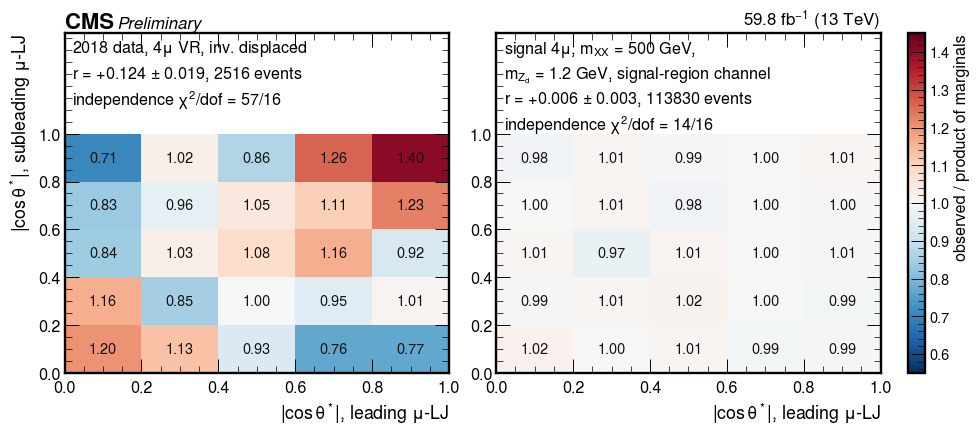

In [25]:
c_pair_plane = lib.fig_pair_plane()

In [26]:
_ = lib.pair_correlation_table()

set                             channel   N events         r  sigma(r)     chi2/ndof          p
--------------------------------------------------------------------------------------------
2018 data                        4mu VR       2516   +0.1238    0.0191    56.9/16     1.73e-06


signal m_XX=500 m_Zd=0.25           4mu     221147   +0.0032    0.0021    13.8/16     6.12e-01
signal m_XX=500 m_Zd=0.25        4mu SR       1046   +0.0650    0.0299    14.3/16     5.75e-01
signal m_XX=500 m_Zd=1.2            4mu     612039   +0.0012    0.0013    15.6/16     4.83e-01


signal m_XX=500 m_Zd=1.2         4mu SR     113830   +0.0056    0.0031    14.4/16     5.68e-01
signal m_XX=500 m_Zd=5.0            4mu     577407   +0.0009    0.0013    20.7/16     1.89e-01
signal m_XX=500 m_Zd=5.0         4mu SR      90380   +0.0034    0.0033    19.7/16     2.35e-01


signal m_XX=1000 m_Zd=0.25          4mu     119069   -0.0007    0.0029    18.2/16     3.15e-01
signal m_XX=1000 m_Zd=0.25       4mu SR        634   -0.0327    0.0397    11.6/16     7.72e-01
signal m_XX=1000 m_Zd=1.2           4mu     422821   +0.0015    0.0015    23.9/16     9.22e-02


signal m_XX=1000 m_Zd=1.2        4mu SR      60283   +0.0042    0.0040    25.6/16     5.94e-02
signal m_XX=1000 m_Zd=5.0           4mu     450601   +0.0021    0.0015    23.3/16     1.05e-01
signal m_XX=1000 m_Zd=5.0        4mu SR      79170   -0.0025    0.0036    16.8/16     3.97e-01


In [27]:
factorisation_rows = lib.pair_factorisation_table()

2018 data, four-muon inverted-displacement validation region: cut on both mu-LJs
ordered   = joint / (leading-jet efficiency x subleading-jet efficiency)
inclusive = joint / (one pooled per-jet efficiency)^2
 threshold  both pass  eff lead  eff sub           ordered  eff pooled         inclusive  events kept
--------------------------------------------------------------------------------------------------------
  |cos| > 0.2     0.5429    0.7262   0.7269    1.029 +- 0.008      0.7266    1.029 +- 0.008         1366
  |cos| > 0.4     0.2758    0.4944   0.5064    1.102 +- 0.020      0.5004    1.102 +- 0.020          694
  |cos| > 0.6     0.1081    0.3136   0.2905    1.187 +- 0.046      0.3021    1.185 +- 0.046          272
  |cos| > 0.8     0.0103    0.1157   0.0636    1.405 +- 0.240      0.0896    1.286 +- 0.221           26


In [28]:
_ = lib.composition_excess_bound(observed=factorisation_rows)

excess over the squared per-jet fraction that the mixture of pair types alone makes
if both muon LJs of an event always share a pair type and are independent within it
2018 data; shares p and fractions f per pair type PF-PF / PF-DSA / DSA-DSA; percent
    region                   | cut at |         p         |         f         |        bound | observed incl. |  observed ord.
    --------------------------------------------------------------------------------------------------------------------------
    4mu inv.-displaced VR    |   0.40 | 0.711 0.287 0.002 | 0.594 0.268 0.333 |   8.7 +-  1.1 |   10.2 +-  2.0 |   10.2 +-  2.0
                             |   0.80 | 0.711 0.287 0.002 | 0.112 0.033 0.000 |  16.2 +-  3.6 |   28.6 +- 22.1 |   40.5 +- 24.0
    2-LJ inv.-displaced CR   |   0.40 | 0.588 0.411 0.000 | 0.622 0.165 0.245 |  26.9 +-  0.2 |   not measured |   not measured
                             |   0.80 | 0.588 0.411 0.000 | 0.065 0.008 0.026 |  45.5 +-  0.9 |   not measured

  wrote sidm/studies/mulj_decay_angle/figures/i2_pair_conditionals.pdf


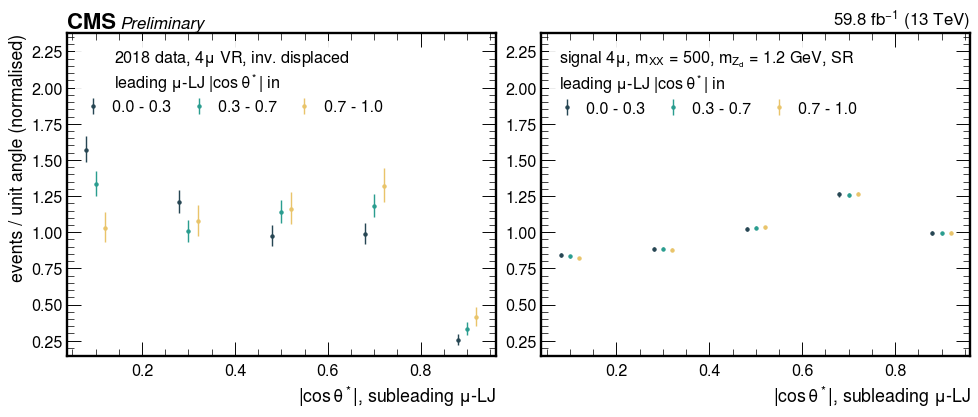

In [29]:
c_pair_cond = lib.fig_pair_conditionals()

How to read these figures: in the validation-region data the cells along the diagonal are
enhanced, 1.20 where both lepton jets sit below 0.2 and 1.40 where both sit above 0.8, and the
two off-diagonal corners are depleted to 0.71 and 0.77.  The linear correlation coefficient is
+0.124 +- 0.019 on 2516 events, and the independence chi-square is 57 for 16 degrees of freedom,
a probability of 2 in a million.

Signal is consistent with independence, with two qualifications.  In the **inclusive** four-muon
channel, where each point carries between 119,000 and 612,000 events, the coefficient at
m_XX = 500 and 1000 GeV is at most +0.003 in absolute value and the independence chi-square runs
from 14 to 24 for the same 16 degrees of freedom.  In the **signal-region** channel, where the
samples are one to two orders of magnitude smaller, two points are less quiet: m_XX = 500 GeV
with m_Zd = 0.25 GeV gives +0.065 +- 0.030 on 1046 events, 2.2 standard deviations, and
m_XX = 1000 GeV with m_Zd = 1.2 GeV has a coefficient consistent with zero, +0.004 +- 0.004, but
an independence chi-square of 26 for 16 degrees of freedom, a probability of 0.059.  Neither is
significant among twelve sets and neither is a reason to distrust the signal side; both are
reasons not to carry "every signal point is consistent with independence, coefficient below
0.006" as a statement about the whole grid, because it is a statement about the inclusive channel
only.  The m_XX = 100 GeV points, below the masses the search uses, are correlated at the +0.09 to
+0.11 level in **both** channels.

One limit of scope, which sets what any of this can be carried to: the four-muon pair grid this
campaign ran holds m_XX = 100, 500 and 1000 GeV only.  The 200 to 250 GeV range at the low edge
of the search is not in it, and is bracketed by the 100 and 500 GeV points rather than measured.

Fake muon lepton jets in one event are therefore correlated with each other and signal ones are
not, which is what a cause shared by the whole event produces: the trigger that selected it, its
kinematics, or the source of its fake muons.

The second figure says the same thing without a model: it normalises the subleading jet's angle
separately in three slices of the leading jet's.  In signal the three curves lie on top of each
other.  In the data they do not: with the leading jet below 0.3 the subleading density falls from
1.57 to 0.99 across the first four bins, and with the leading jet above 0.7 it rises from 1.03 to
1.32 over the same range.  Both slices drop in the last bin, where the acceptance edge of
section g bites.

The practical consequence is in the printed table, and how large it is depends on what "the
per-lepton-jet rate" is taken to mean, so the table prints both.  Against **one inclusive
per-jet efficiency squared** (the usual shorthand, with both lepton jets of every event pooled
into one sample), a requirement applied to both jets keeps 1.029 +- 0.008 times as many
validation-region events at a threshold of 0.2, 1.102 +- 0.020 at 0.4, 1.185 +- 0.046 at 0.6 and
1.286 +- 0.221 at 0.8.  Against the **product of the two ordered marginals** (the leading jet's
rate times the subleading jet's, which at the tightest threshold are 0.116 and 0.064 and so are
not the same number), they are 1.029, 1.102, 1.187 and 1.405 +- 0.240.

In summary: about 10 percent at a threshold of 0.4, where the two
definitions agree to three decimals and the uncertainty is a fifth of the effect, and roughly 30
percent at 0.8, on the 26 events that pass it, where the inclusive definition gives 1.29 and the
ordered one 1.41, the two differ by half of either uncertainty, and neither is more than about
1.3 standard deviations from unity.  An event-level background rate obtained by squaring a
per-jet efficiency is optimistic by an amount that is measured at 0.4 and only indicated at 0.8,
and the two angles are not two independent axes for a factorised background estimate in this
region.  The composition table bounds what the mixture of pair types can contribute: if the two
jets of an event always shared a pair type, the mixture alone would give an excess of
8.7 +- 1.1 percent at 0.4 and 16 +- 4 percent at 0.8 over the square of the pooled per-jet
fraction, against the 10.2 +- 2.0 and 29 +- 22 percent observed.

### Does the angle still separate inside a mass window

The four-muon validation region cuts the muon-lepton-jet-pair mass at 150 GeV, and the four-muon
search reads that mass; the question here is what the angle adds once a window on it has been
taken. The table gives the shape of the angle window by window in the validation-region data, the
first figure draws it, and the second asks what a cut, or the whole shape, would buy inside the
window each signal point actually fills.

In [30]:
_ = lib.pair_window_table()

2018 data, four-muon inverted-displacement validation region, one entry per mu-LJ
    m(muLJ,muLJ)   pairs   shape of |cos(theta*)| in 5 bins            mean  chi2/4 vs all
------------------------------------------------------------------------------------------------
     150-200 GeV    3009   0.280 0.234 0.205 0.213 0.069      0.411 +- 0.005           16.2
     200-250 GeV    1186   0.259 0.223 0.191 0.215 0.111      0.439 +- 0.008            7.6
     250-300 GeV     436   0.280 0.193 0.206 0.209 0.112      0.436 +- 0.013            4.9
     300-380 GeV     257   0.268 0.214 0.152 0.214 0.152      0.453 +- 0.018           14.2
     380-500 GeV     101   0.218 0.267 0.208 0.168 0.139      0.449 +- 0.027            5.6
     500-600 GeV      26   0.346 0.115 0.115 0.308 0.115      0.446 +- 0.058            4.1
     600-780 GeV      20   0.250 0.150 0.200 0.100 0.300      0.510 +- 0.070           11.6
    780-1000 GeV       2   too few pairs to measure a shape
      > 1000 GeV       2  

  [note] data, > 600 GeV: 24 entries over 5 bins, below what this study draws a shape at; not drawn


  wrote sidm/studies/mulj_decay_angle/figures/i3_window_shapes.pdf


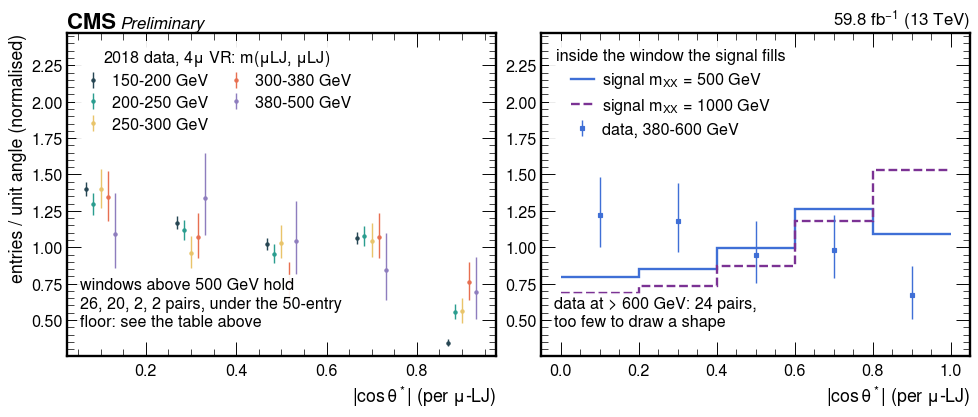

In [31]:
c_window_shapes = lib.fig_window_shapes()

In [32]:
gain_rows = lib.pair_gain_table()

signal channel 4mu_sr; fakes from the four-muon inverted-displacement VR
  m_XX  m_Zd       window  fake pairs               best cut             shape gain    vs pooled fakes
----------------------------------------------------------------------------------------------------------
   500  0.25  380-600 GeV         127      |cos| > 0.2: 0.91         1.015 +- 0.024     1.016 +- 0.011


   500  1.20  380-600 GeV         127      |cos| > 0.2: 0.97         1.060 +- 0.040     1.049 +- 0.016


   500  5.00  380-600 GeV         127      |cos| > 0.2: 0.97         1.054 +- 0.037     1.045 +- 0.015
  1000  0.25    > 600 GeV          24      |cos| > 0.2: 0.97         1.067 +- 0.148     1.031 +- 0.016


  1000  1.20    > 600 GeV          24      |cos| > 0.2: 1.04         1.095 +- 0.161     1.143 +- 0.034
  1000  5.00    > 600 GeV          24      |cos| > 0.2: 1.02         1.086 +- 0.160     1.091 +- 0.026

shape gain is sqrt(sum f_s^2 / f_b) over the five bins of the angle: the factor by
which a shape fit beats the inclusive count in the same window.  One means nothing
is added.  The bias of the estimator at these sample sizes is printed below.
  m_XX=500 m_Zd=0.25: point 1.015, bootstrap mean 1.033, bias-corrected 0.996 (on 127 fake pairs)
  m_XX=500 m_Zd=1.2: point 1.060, bootstrap mean 1.080, bias-corrected 1.040 (on 127 fake pairs)
  m_XX=500 m_Zd=5.0: point 1.054, bootstrap mean 1.074, bias-corrected 1.034 (on 127 fake pairs)
  m_XX=1000 m_Zd=0.25: point 1.067, bootstrap mean 1.169, bias-corrected 0.966 (on 24 fake pairs)
  m_XX=1000 m_Zd=1.2: point 1.095, bootstrap mean 1.192, bias-corrected 0.999 (on 24 fake pairs)
  m_XX=1000 m_Zd=5.0: point 1.086, bootstrap mean 1.185, bias-c

  wrote sidm/studies/mulj_decay_angle/figures/i4_window_gain.pdf


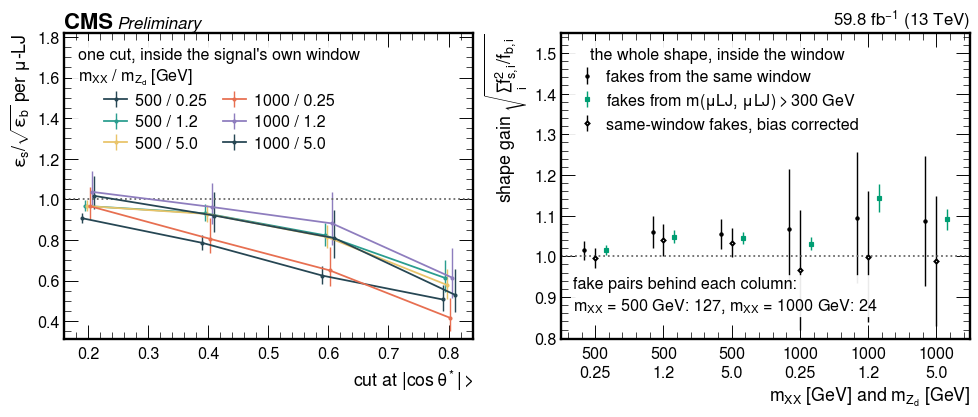

In [33]:
c_window_gain = lib.fig_window_gain(gain_rows)

In [34]:
_ = lib.pair_plane_gain_table()

event level, all event masses: the two-dimensional plane against two one-jet cuts
  m_XX  m_Zd             plane gain    one jet  one jet squared  plane / squared
----------------------------------------------------------------------------------
   500  0.25         1.171 +- 0.037      1.055            1.112            1.053
   500  1.20         1.244 +- 0.028      1.123            1.262            0.986
   500  5.00         1.216 +- 0.025      1.108            1.227            0.991
  1000  0.25         1.293 +- 0.060      1.111            1.235            1.047
  1000  1.20         1.634 +- 0.076      1.309            1.713            0.954
  1000  5.00         1.449 +- 0.051      1.222            1.494            0.970


How to read these: the validation-region data falls steeply in the pair mass.  Of its 5039
lepton-jet entries, 3009 sit in the 150 to 200 GeV window and 151 above 380 GeV.  The window used
for the m_XX = 500 GeV signal is 380 to 600 GeV, which that signal fills to 81 to 94 percent and
which holds 127 fake pairs; the window used for m_XX = 1000 GeV is everything above 600 GeV,
which that signal fills to 93 to 99 percent and which holds **24** fake pairs.  Those two numbers,
127 and 24, are what the table, both figures and every gain below are built on.

The fake shape is not the same in every window: the mean angle rises from 0.411 +- 0.005 at 150
to 200 GeV to 0.449 +- 0.027 at 380 to 500 GeV, and the lowest window alone contributes 16 to the
chi-square against the pooled shape.  A fake shape measured where the data is cannot be carried
unchanged to where the signal is.  The left panel of the first figure draws the five windows from
150 to 500 GeV.  The four windows above it (500 to 600, 600 to 780,
780 to 1000 and above 1000 GeV) hold 26, 20, 2 and 2 pairs, every one below the fifty-entry floor this study draws a shape
at, so they are named on the panel itself and read from the table above it instead of being drawn
as a picket fence of five bins holding four entries each.

Inside the window the signal fills, the separation is small.  At m_XX = 500 GeV the signal keeps
84 percent of its lepton jets above 0.2 while the data in the same window keeps 76 percent, a
signal over root background factor of 0.97: the best of the four thresholds does not improve the
sensitivity, and every tighter one makes it worse, down to 0.6 at a threshold of 0.8.  Using the
whole five-bin shape instead of one cut gives 1.060 +- 0.040 at m_XX = 500 GeV, m_Zd = 1.2 GeV
and 1.095 +- 0.161 at 1000 GeV.  That estimator is biased upwards when the background sample is
small, because noise in a background bin reads as separation; resampling puts the bias at +0.02
on the 127 fake pairs of the 500 GeV window and +0.10 on the 24 of the 1000 GeV one, so the
bias-corrected values are 1.040 +- 0.040 and 0.999 +- 0.161.  The right panel of the second
figure draws those corrected values as open markers beside the raw ones, because the raw points
on their own read as six numbers above one while the correction moves the three heavy ones onto
it.

So the answer at m_XX = 500 GeV is a corrected gain of 1.040 +- 0.040, one standard deviation from
unity: **consistent with no gain, and at most a few percent per lepton jet**.  At 1000 GeV the three
corrected values are 0.966, 0.999 and 0.987 with an uncertainty of 0.15 to 0.16 on 24 fake pairs,
so no gain can be distinguished there.  Measured instead against the larger pooled fake
sample above 300 GeV, which assumes the mass independence the window table has just rejected,
the raw values are 1.016 to 1.049 at 500 GeV and 1.031 to 1.143 at 1000 GeV.

The last table repeats the exercise on the plane of both angles, where the data sample is large
enough to measure something: over all pair masses the plane reaches 1.244 +- 0.028 at
m_XX = 500 GeV, m_Zd = 1.2 GeV and 1.634 +- 0.076 at 1000 GeV, which is 0.99 and 0.95 of the
square of the corresponding one-jet number.  The correlation among fakes costs a few percent of
what two independent lepton jets would have given, no more.  That comparison is inclusive in the
pair mass, and the difference between it and the per-window numbers is the point.  The natural
reading of that difference is that most of the inclusive separation is the steeper angular shape
of the low-mass fakes and the mass window removes it.  That is an **inference** from the two
sets of numbers side by side, not a measurement: nothing here decomposes the inclusive gain into a
mass-shape part and an angle-shape part, and the study would need the gain recomputed window by
window on a fake sample large enough to support it before the reading could be called
established.

### What the pair says

Fake pairs are correlated and signal pairs are not.  In the four-muon validation region the
two decay angles of an event have a linear correlation of +0.124 +- 0.019
on 2516 events and an independence chi-square of 57 for 16 degrees of freedom, the excess sitting
on the diagonal.  In the inclusive four-muon channel every signal point that still matters is
consistent with independence at the +-0.003 level; in the smaller signal-region channel two of
the twelve sets sit at about two standard deviations, which chance alone produces among twelve
sets.  The
arithmetic consequence is that an event rate built by squaring a per-lepton-jet efficiency is
optimistic here by about 10 percent at a threshold of 0.4, where the measurement is solid, and by
roughly 30 percent at 0.8, where it rests on 26 events and the two reasonable definitions of the
per-jet rate differ by half their own uncertainty.  So the squaring shorthand of
section h fails for fakes; for signal, whose two jets are independent, it stands.

Inside a mass window the angle adds nothing this data can resolve.  The validation data falls
steeply in the pair mass and its angular shape is itself mass dependent, so the fake shape has to
be measured where the signal is, and there it rests on 127 pairs at m_XX = 500 GeV and 24 above
600 GeV.  No single threshold helps.  The whole five-bin shape gives a bias-corrected gain of
1.040 +- 0.040 per lepton jet at 500 GeV (consistent with no gain, at most a few percent) and
0.97 to 1.00 with an uncertainty of 0.16 at 1000 GeV.  The larger inclusive numbers, 1.24 and
1.63 for the two-angle plane over all pair masses, are most naturally read as the low-mass fakes'
steeper shape, which the window removes; that reading is an inference from the two sets of
numbers, not a decomposition this study performs.

Both readings inherit the study's caveats.  The validation region requires a muon with more
than two pixel hits in each muon lepton jet, which leaves 29 percent of its muon pairs with a
displaced-standalone muon (caveat 2).  That mixture matters for the factorisation test: the
particle-flow and mixed pairs of this region have unlike shapes (0.59 against 0.27 above 0.4),
and if the two jets of an event always shared a pair type the mixture alone would produce an
excess of 8.7 +- 1.1 percent at 0.4 and 16 +- 4 percent at 0.8 over the square of the pooled
per-jet fraction, against the 10.2 +- 2.0 and 29 +- 22 percent observed (against the product of
the two ordered per-jet fractions the observed excess at 0.8 is 40.5 +- 24.0 percent).  The
uncertainty on the bound resamples events, not jets, since the two jets of an event are
correlated.  The pair type of the two jets
is not recorded jointly in these histograms, so the study cannot say how much of the excess is
angular correlation at fixed pair type and how much is shared composition.  For an estimate that
squares an inclusive per-jet efficiency the consequence is the same.  Nothing here shows that a
fake shape measured in the validation region transfers to the signal region, and the grid stops
short of the 200 to 250 GeV bound-state masses at the low edge of the search.  The
recommendation keeps section h's direction and sharpens its size: do not add the decay angle to
the four-muon selection or to its background estimate, and do
keep the pair correlation as a measured fact about fakes: the two muon lepton jets of a fake
four-muon event are not independent, which any factorised estimate in that channel must face.

## j. The lepton jets as a decay-plane system

Sections b to i take the decay angle of one muon lepton jet, and then the two of a four-muon
event.  The decay-plane campaign (`LjAnglePlanes_Run2018_v1`) completes the construction.  It adds three
things: the **signed** decay angle, so that the negatively charged lepton picks a direction and
not only an axis; the same pair of quantities for the two leading **electrons** of an
electromagnetic lepton jet; and the event-level observables of the two leading qualifying lepton
jets of either type (their two helicity angles in the rest frame of their sum, the azimuthal
angle between their two decay planes, their transverse balance, and the missing transverse
momentum with and without the displaced-standalone muons added back).

Why the plane angle is worth a section.  The signal as generated is **CP even**: the bound state
of mass m_XX that decays to the two dark photons (in the generator model a scalar field phi)
couples to them through a field-strength operator, phi F F, which produces only transverse dark
photons.  Each dark photon decay then follows 1 + alpha cos^2(theta*) in its own
rest frame, with alpha = beta*^2 / (2 - beta*^2), and the azimuthal angle Phi between the two
decay planes follows 1 + A cos(2 Phi) with A = [beta*^2 / (3 - beta*^2)]^2, the product of the two
decays' analyzing powers.  The planes are preferentially parallel, with A = +1/4 for massless leptons, 0.228 for
muons at m_Zd = 1.2 GeV and 0.011 at 0.25 GeV, all for an unselected sample.  A CP-odd parent of
the same mass would give 1 - A cos(2 Phi), the same magnitude with the opposite sign.  That is
the one place in this whole study where the
angles carry information about what the parent *is* rather than about how clean the lepton jet
is.

What the reconstructed distribution can and cannot say about that is the point of the section,
and the answer is set by two facts stated here once.  First, the **reference is never the
analytic curve**: the production filter of the sample (four leptons above 5 GeV within
|eta| < 2.4) and then the channel's own selection both reshape the truth distribution, so every
reconstructed distribution below is compared with the **generator-level histogram from the same
files and the same channel**, and the analytic +1/4 is drawn only as the unsculpted
massless-lepton reference it is.  Second, in the lab frame the energy asymmetry of a pair is
(E1 - E2) / (E1 + E2) = beta beta* cos(theta*), with beta the dark photon's speed in the lab and
beta* the lepton's in the dark-photon rest frame, so as |cos(theta*)| approaches one, one lepton
goes soft and falls below threshold: the reconstructed angular shapes are acceptance sculpted and
are **not** a polarization measurement without an efficiency map.  Electrons are worse than muons,
because bremsstrahlung moves energy out of the electron and into photons the pair does not
carry.

Collision data was written in control and validation regions only; the loader refuses to open a
data file in any other channel rather than trusting the caller.  The search uses bound-state
masses of 200 GeV and above, so every number is led by m_XX = 500 and 1000 GeV.  This
campaign's grid holds 100, 500 and 1000 GeV only, so the 200 to 250 GeV range is bracketed by it,
not covered.

In [35]:
# the decay-plane campaign has its own merged outputs, so this is a third input directory
#
#   campaign   : LjAnglePlanes_Run2018_v1  (submitted 2026-09-02; 7,096 jobs, 154 samples)
#   merged     : /store/group/lpcmetx/SIDM/coffea_outputs/murtazas/lj_angle_planes
#                and the local copy below; merged and read on 2026-09-05
#   collections: lj_decay_angle, lj_pair_decay_planes, and lj_pair_decay_planes_gen on signal
lib.configure_planes("/uscms_data/d3/murtazas/lj_angle_planes_merged")
lib.planes_inventory()

campaign      : LjAnglePlanes_Run2018_v1
merged inputs : /uscms_data/d3/murtazas/lj_angle_planes_merged


signal points : 4Mu [(100.0, 0.25), (100.0, 1.2), (100.0, 5.0), (500.0, 0.25), (500.0, 1.2), (500.0, 5.0), (1000.0, 0.25), (1000.0, 1.2), (1000.0, 5.0)]
                2Mu2E [(100.0, 0.25), (100.0, 1.2), (100.0, 5.0), (500.0, 0.25), (500.0, 1.2), (500.0, 5.0), (1000.0, 0.25), (1000.0, 1.2), (1000.0, 5.0)]
data samples  : 68
bkg samples   : 20
data channels : cr_2lj_invDisplaced_spread_cosAlpha_mu_veto, data_control_region_1egmLj_cosmic_veto, data_control_region_1muLj_spread_cosAlpha_mu_veto, test_VR_2mu2e_invDisplaced_spread_cosAlpha_mu_veto, test_VR_4mu_invDisplaced_spread_cosAlpha_mu_veto


### Where the decay angle of a muon lepton jet lives, mass by mass

The first figure puts the decay angle against the dimuon mass of the same pair, and normalises
every mass row on its own.  That is the comparison that does not depend on the mass spectra of
signal and fakes being wildly different: at a given dimuon mass, is the angle distributed
differently?

  wrote sidm/studies/mulj_decay_angle/figures/j1_mulj_mass_angle.pdf


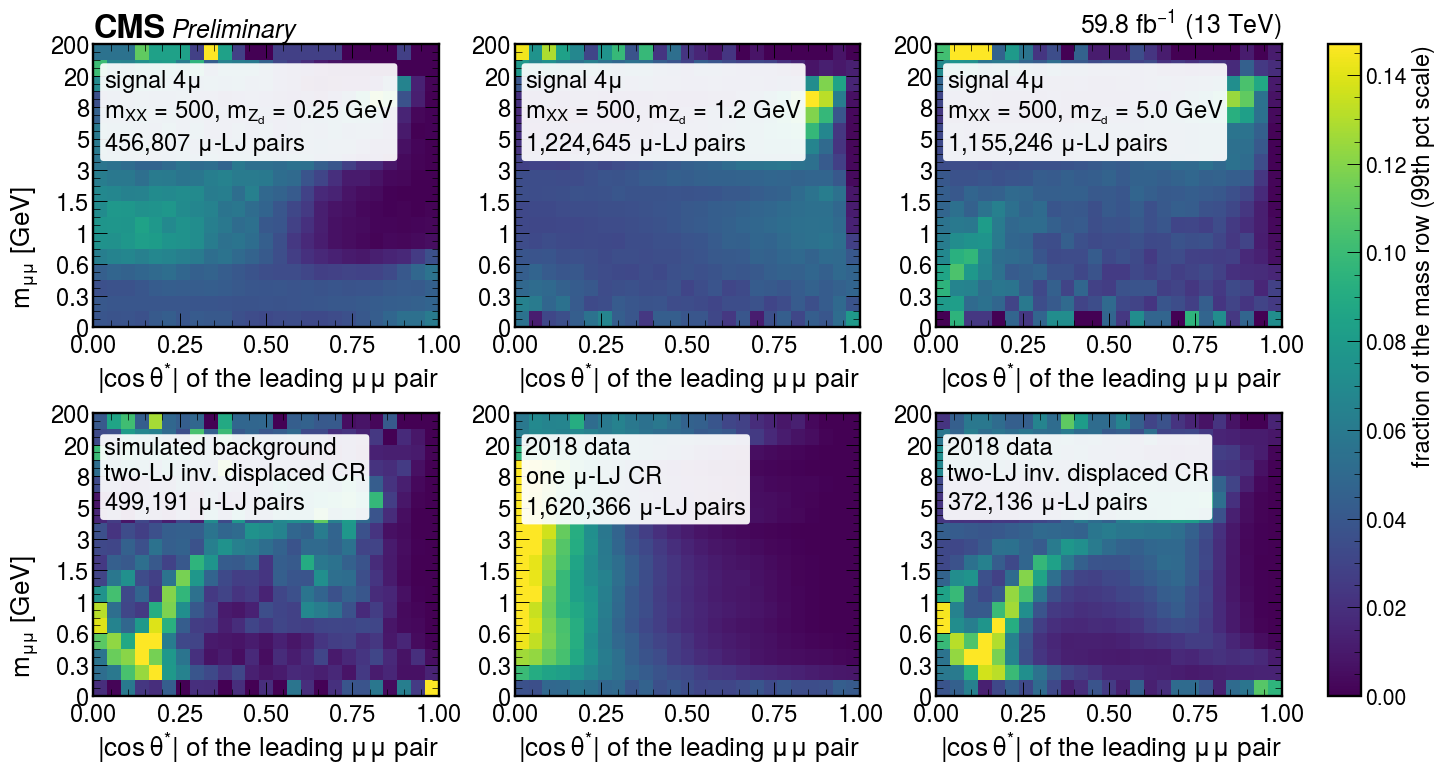

In [36]:
c_mulj_plane = lib.fig_mulj_mass_angle(m_xx=500.0)

  wrote sidm/studies/mulj_decay_angle/figures/j2_mulj_angle_overlays.pdf


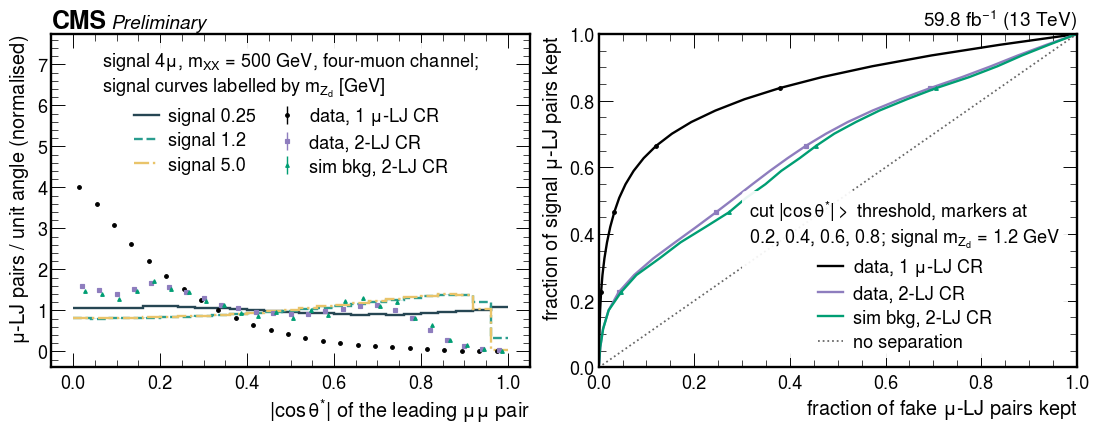

In [37]:
c_mulj_overlay = lib.fig_mulj_angle_overlays(m_xx=500.0)

In [38]:
mu_rows = lib.planes_mu_separation_table()

muon-LJ |cos(theta*)|: one entry per mu-LJ with two or more muons
set                                    channel      pairs            <|cos|>   eff(>0.2)  eff(>0.4)  eff(>0.6)  eff(>0.8)
----------------------------------------------------------------------------------------------------------------------
4Mu 500/0.25                               4mu     456807 0.4876 +- 0.0004      0.7866     0.5726     0.3793     0.1988
4Mu 500/1.2                                4mu    1224645 0.5369 +- 0.0003      0.8380     0.6649     0.4658     0.2254
4Mu 500/5.0                                4mu    1155246 0.5292 +- 0.0003      0.8360     0.6603     0.4561     0.2091
4Mu 1000/0.25                              4mu     268193 0.5122 +- 0.0006      0.8062     0.6030     0.4096     0.2329
4Mu 1000/1.2                               4mu     847603 0.5795 +- 0.0003      0.8601     0.7084     0.5283     0.2937
4Mu 1000/5.0                               4mu     901827 0.5601 +- 0.0003      0.8512     0.

sim bkg, two-LJ invDisp CR     2 LJ invDisp CR     499191 0.3264 +- 0.0004      0.7060     0.4551     0.2730     0.0466

signal efficiency over root fake efficiency, per mu-LJ, at |cos(theta*)| > 0.4
signal point                         data, one mu-LJ CR     data, two-LJ invDisp CR        data, 4mu invDisp VR  sim bkg, two-LJ invDisp CR
------------------------------------------------------------------------------------------------------------------------
4Mu 500/0.25                                      1.650                       0.869                       0.810                       0.849
4Mu 500/1.2                                       1.916                       1.010                       0.940                       0.986
4Mu 500/5.0                                       1.903                       1.003                       0.934                       0.979
4Mu 1000/0.25                                     1.738                       0.916                       0.853        

In [39]:
_ = lib.pair_type_separation(threshold=0.4, m_xx=500.0, m_zd=1.2)

signal 4mu, m_XX = 500 GeV, m_Zd = 1.2 GeV: eff(|cos theta*| > 0.40) = 0.6649
against the data pairs of the 2-LJ inv.-displaced CR, cut at 0.40
    fake pairs |     pairs |  eff_b | eff_s/sqrt(eff_b)
    all        |   372,137 |  0.434 |             1.010
    PF-PF      |   218,907 |  0.622 |             0.843
    PF-DSA     |   153,079 |  0.165 |             1.638
    DSA-DSA    |       151 |  0.245 |             1.343


How to read these: every mass row is normalised on its own, so a cell's colour says how the
angle is distributed **at that dimuon mass**, not how many pairs sit there; the colour scale is
capped at the 99th percentile so that one sparsely filled row cannot set it for all six panels.

Two features carry the figure.  In the signal panels the row at the dark photon's own mass is
spread nearly flat across the angle, which is the decay; the brightest cells sit elsewhere, at
high dimuon mass and high |cos(theta*)|, and they are the pairs whose two hardest muons are not
one dark photon's: a muon lepton jet may hold more than two muons and this study always takes
the two hardest, as section a says.  In the fake panels the population traces a **ridge**: the
angle a pair reconstructs climbs steadily with its dimuon mass, from a fraction of a GeV up to a
few GeV, and there is no comparable population anywhere else in the plane.  The same ridge is
visible in the signal panels at dimuon masses well below the dark photon's, where the pair is
again not a decay, so it is a property of accidental pairs rather than of the fake samples; that
reading follows from where the ridge appears and is not separately demonstrated here.

The one-dimensional overlays and the printed table put numbers on it, and the numbers say that
the size of the separation is set almost entirely by
**which fake sample it is measured against**.  A threshold at |cos(theta*)| > 0.4 keeps 0.66 to
0.71 of signal muon-lepton-jet pairs at m_XX = 500 and 1000 GeV with m_Zd = 1.2 or 5.0 GeV.  The
same threshold keeps 0.120 of the pairs in the cleaned single-lepton-jet control region, 0.434
of those in the two-lepton-jet control region, and 0.500 of those in the four-muon validation
region.  The resulting signal efficiency over root fake efficiency is 1.9
against the first and 1.0 against the second: against the control region whose event topology
actually resembles the signal region, two lepton jets rather than one, the handle is worth
nothing.

The right-hand panel is the same statement without a threshold: the curve against the
cleaned single-lepton-jet control region bows well above the diagonal, and the curve against the
two-lepton-jet control region lies almost on it.  This is the sharpest form of the warning
of sections e and h, that a fake shape measured in one region does not transfer, and here it is
measured rather than argued.  Against the cleaned single-lepton-jet control region the
m_Zd = 0.25 GeV signal column is below the heavier masses in four-muon (1.65 and 1.74 against
1.90 to 2.04 at m_XX = 500 and 1000 GeV) and level with them in two-muon-two-electron at
m_XX = 500 GeV (1.62 against 1.59 and 1.61): a nearly flat decay still separates against steeply
falling fakes, though the angle at that mass carries the single-precision arithmetic of
section b.  The simulated background is shown
with its cross-section weights and rests on far fewer effective entries than the data.

### The electron pair of an electromagnetic lepton jet

The same construction on the two leading electrons of an electromagnetic lepton jet.  Before any
shape is read, one number has to be quoted: **how often the two electrons are reconstructed
separately at all**.  A dark photon of low mass is highly boosted, its two electrons merge into
one supercluster plus photons, and the lepton jet then holds one electron, which no electron-pair
histogram is filled from.

In [40]:
egm_rows = lib.planes_egm_resolved_table()

egamma-type LJs holding two or more reconstructed electrons
set                                    channel    egm LJs  with 2+ e   fraction  ee entries
------------------------------------------------------------------------------------------


2Mu2E 100/0.25                           2mu2e       2036         32    0.01572          32


2Mu2E 100/1.2                            2mu2e       2898        606    0.20911         606
2Mu2E 100/5.0                            2mu2e       2393        721    0.30130         721
2Mu2E 500/0.25                           2mu2e     109724         13    0.00012          13


2Mu2E 500/1.2                            2mu2e     228800       3613    0.01579        3613
2Mu2E 500/5.0                            2mu2e     184018      53527    0.29088       53527
2Mu2E 1000/0.25                          2mu2e      53343          8    0.00015           7
2Mu2E 1000/1.2                           2mu2e     175740        299    0.00170         299
2Mu2E 1000/5.0                           2mu2e     143602      15084    0.10504       15084
data, one egm-LJ CR                 1 egmLJ CR      57943        257    0.00444         257
data, two-LJ invDisp CR        2 LJ invDisp CR      65856        575    0.00873         575
data, 2mu2e invDisp VR        2mu2e invDisp VR       7447         64    0.00859          64
sim bkg, two-LJ invDisp CR     2 LJ invDisp CR      71405        535    0.00749         534

A pair histogram of an egamma-type LJ is filled only by the resolved fraction
above, so every electron-pair number below is a statement about that subset and
not about the

  wrote sidm/studies/mulj_decay_angle/figures/j3_egm_ee.pdf


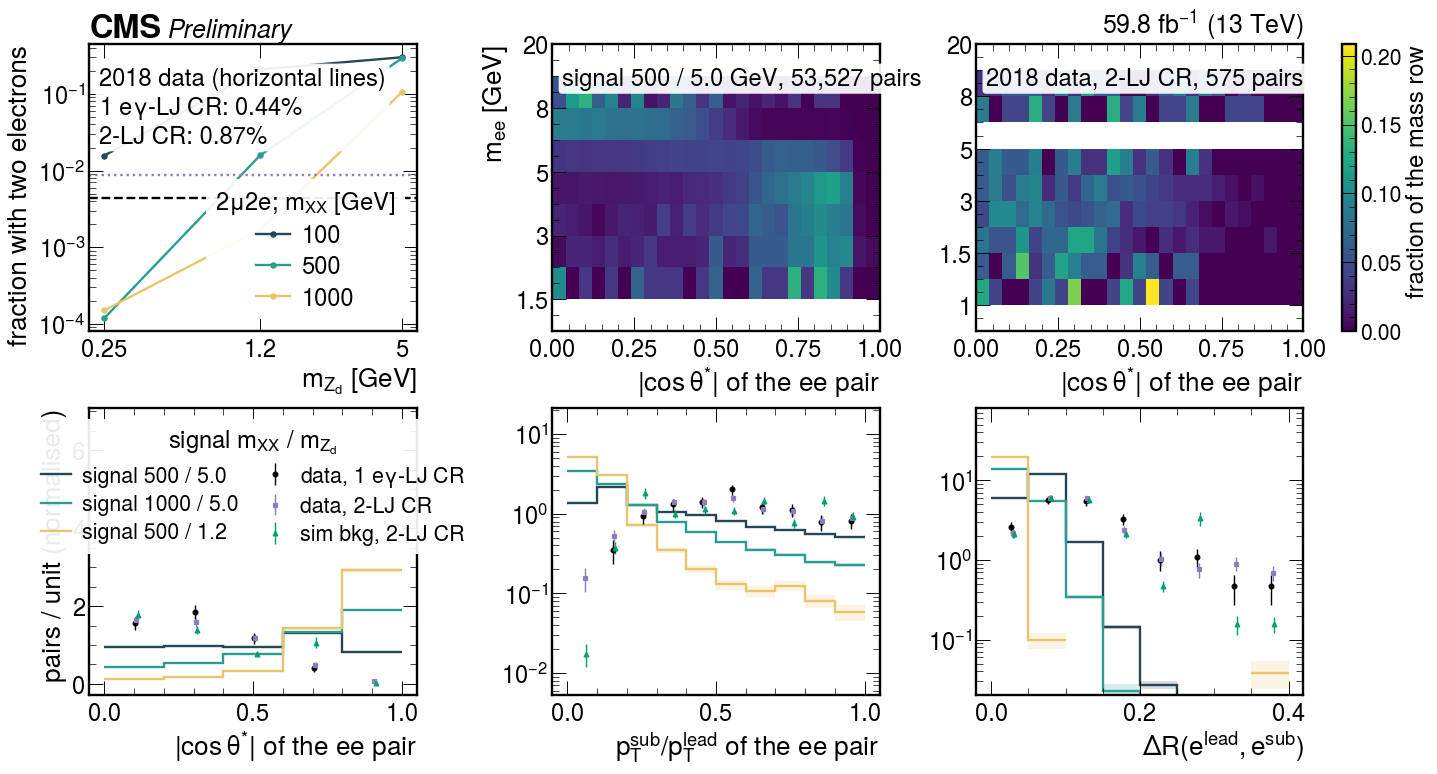

In [41]:
c_egm = lib.fig_egm_ee()

In [42]:
_ = lib.planes_egm_shape_table()

resolved electron pairs of egamma-type LJs
set                                    channel    pairs            <|cos|>          <ptRatio>               <dR>
----------------------------------------------------------------------------------------------------------------
2Mu2E 500/0.25                           2mu2e       13 0.6631 +- 0.0679 0.2408 +- 0.0611 0.2273 +- 0.0369   (below the shape floor)
2Mu2E 500/1.2                            2mu2e     3613 0.7602 +- 0.0030 0.1522 +- 0.0026 0.0250 +- 0.0004
2Mu2E 500/5.0                            2mu2e    53527 0.4965 +- 0.0012 0.3849 +- 0.0012 0.0664 +- 0.0001
2Mu2E 1000/0.25                          2mu2e        7 0.5800 +- 0.1190 0.3125 +- 0.1015 0.1800 +- 0.0447   (below the shape floor)
2Mu2E 1000/1.2                           2mu2e      299 0.8667 +- 0.0073 0.0774 +- 0.0060 0.0354 +- 0.0040
2Mu2E 1000/5.0                           2mu2e    15084 0.6434 +- 0.0021 0.2537 +- 0.0019 0.0458 +- 0.0002
data, one egm-LJ CR                 1

data, two-LJ invDisp CR        2 LJ invDisp CR      575 0.3274 +- 0.0086 0.5419 +- 0.0098 0.1347 +- 0.0036


sim bkg, two-LJ invDisp CR     2 LJ invDisp CR      534 0.3204 +- 0.0092 0.5641 +- 0.0104 0.1332 +- 0.0037


How to read these: the resolved fraction sets what the electron channel can do.  At
m_Zd = 5.0 GeV it is 29 percent of electromagnetic lepton jets at m_XX = 500 GeV and 10.5 percent
at 1000 GeV; at m_Zd = 1.2 GeV it falls to 1.6 percent and 0.17 percent; at m_Zd = 0.25 GeV it is
about one in ten thousand, 13 lepton jets of 110,000 at m_XX = 500 GeV.  The trend is exactly the
boost: heavier bound state, more boost, more merging, and lighter dark photon likewise.  In the
data the fraction is 0.44 percent in the electromagnetic-lepton-jet control region and 0.87
percent in the two-lepton-jet control region.

That fraction also limits how the shapes can be read.  The resolved pairs at
m_Zd = 1.2 GeV are not a representative tenth of the decays: they are the asymmetric tail that
happened to split, with a mean momentum ratio of 0.15 against 0.38 at m_Zd = 5.0 GeV and a mean
|cos(theta*)| of 0.76 against 0.50.  A cut placed on the electron-pair angle would therefore be
acting on a sample that is already selected by whether the pair resolved, and what the numbers
support is that the electron pair separates from the fake control regions strongly (mean
|cos(theta*)| of 0.50 to 0.87 in signal against 0.31 to 0.33 in data), **on the subset where it
exists at all**, which at the masses the search cares about is a few percent of electromagnetic
lepton jets or less.  The panels draw only the shapes with enough entries to draw; the data
control regions carry 257 and 575 resolved pairs and are rebinned to five bins for that
reason.

### The two helicity angles of the lepton-jet pair

Section i asked whether the two **absolute** decay angles of a four-muon event are correlated.
The pair histograms of this campaign carry the **signed** helicity angle of each of the two
leading qualifying lepton jets, measured in the rest frame of their sum, which is the angle the
decay-plane construction actually uses.  The figure is built exactly as section i's is: the
observed plane divided by the product of its own two marginals, so a plane of ones is
independence.

  wrote sidm/studies/mulj_decay_angle/figures/j4_pair_helicity_plane.pdf


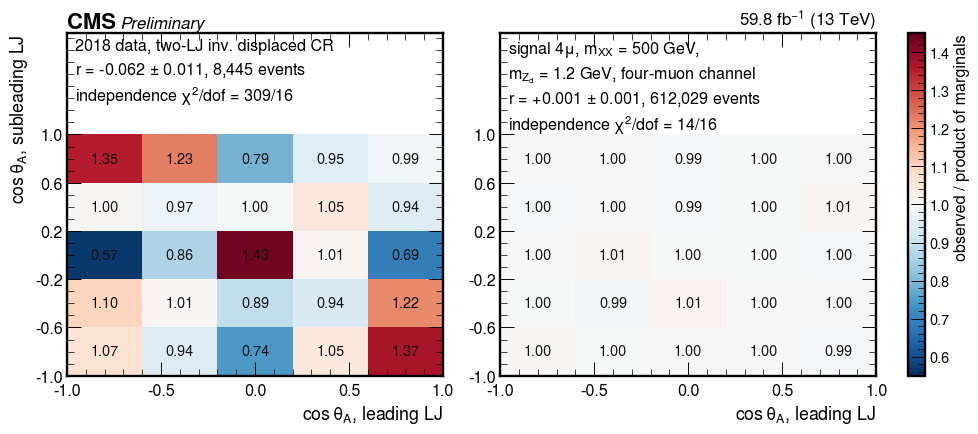

In [43]:
c_pair_helicity = lib.fig_pair_helicity_plane(point=(500.0, 1.2))

In [44]:
pair_rows = lib.planes_pair_correlation_table()

linear correlation of cos(theta_A) between the two leading lepton jets
set                                channel    events         r  sigma(r)     chi2/ndof         p
-----------------------------------------------------------------------------------------------
2018 data                  2 LJ invDisp CR      8445   -0.0624    0.0108    309.4/16       0.000
2018 data                   4mu invDisp VR      2516   -0.0525    0.0209     51.7/16       0.000
2018 data                 2mu2e invDisp VR        86   -0.1486    0.1105     18.5/16       0.293


simulated background       2 LJ invDisp CR     21924   -0.0059    0.0074    600.8/16       0.000
4Mu 500/0.25                           4mu    222249   +0.0006    0.0021     16.6/16       0.415
4Mu 500/1.2                            4mu    612029   +0.0010    0.0012     14.2/16       0.582
4Mu 500/5.0                            4mu    577414   -0.0008    0.0013     15.3/16       0.502
4Mu 1000/0.25                          4mu    118475   -0.0052    0.0029     16.2/16       0.440
4Mu 1000/1.2                           4mu    422651   +0.0021    0.0015      8.9/16       0.917


4Mu 1000/5.0                           4mu    450592   +0.0005    0.0014     14.1/16       0.592
2Mu2E 500/0.25                       2mu2e        45   -0.1718    0.1415      9.6/16       0.885
2Mu2E 500/1.2                        2mu2e      3699   +0.0141    0.0154    391.9/16       0.000
2Mu2E 500/5.0                        2mu2e     53564   +0.0006    0.0044     46.1/16       0.000
2Mu2E 1000/0.25                      2mu2e        33   +0.0848    0.1806     11.6/16       0.772
2Mu2E 1000/1.2                       2mu2e       405   +0.0167    0.0483     35.9/16       0.003
2Mu2E 1000/5.0                       2mu2e     15177   +0.0072    0.0079     11.5/16       0.781

the same at generator level, for the signal points that carry a gen record


  gen 4Mu 500/0.25: r = -0.0001 +- 0.0020 on 239,330 events
  gen 4Mu 500/1.2: r = +0.0003 +- 0.0013 on 612,290 events
  gen 4Mu 500/5.0: r = -0.0012 +- 0.0013 on 577,435 events
  gen 4Mu 1000/0.25: r = +0.0204 +- 0.0026 on 155,578 events
  gen 4Mu 1000/1.2: r = +0.0012 +- 0.0016 on 424,721 events
  gen 4Mu 1000/5.0: r = +0.0008 +- 0.0015 on 450,694 events


  gen 2Mu2E 500/0.25: r = -0.0003 +- 0.0029 on 108,969 events
  gen 2Mu2E 500/1.2: r = -0.0034 +- 0.0020 on 227,199 events
  gen 2Mu2E 500/5.0: r = +0.0013 +- 0.0023 on 182,619 events
  gen 2Mu2E 1000/0.25: r = +0.0159 +- 0.0047 on 52,521 events
  gen 2Mu2E 1000/1.2: r = -0.0005 +- 0.0024 on 173,846 events
  gen 2Mu2E 1000/5.0: r = -0.0014 +- 0.0027 on 142,066 events


How to read these: signal is independent and fakes are not, which is section i's conclusion
again, but with the opposite **sign**, and that is worth stating because the two are different
measurements and not two views of one.  On the signed angle the two-lepton-jet control region
gives
r = -0.062 +- 0.011 on 8,445 events and the four-muon validation region -0.053 +- 0.021 on 2,516;
on the absolute angle of section i the same validation-region events gave +0.124 +- 0.019.  A
sample can be positively correlated in |cos| and negatively correlated in cos: the first is a
statement about how central the two pairs are together, the second about whether their two
negative leptons prefer the same hemisphere.  The simulated background has a coefficient
consistent with zero, -0.006 +- 0.007, so the linear effect the data shows is not reproduced by
the simulation; see the second caution below before reading that as independence.

Signal is flat in the four-muon channel on **both** tests: the coefficient is no larger than
0.006 in absolute value at m_XX = 500 and 1000 GeV, on 118,000 to 612,000 events, and the
independence chi-square runs from 9 to 17 for 16 degrees of freedom.  The generator-level planes
of the same samples agree, with one exception, m_XX = 1000 GeV and m_Zd = 0.25 GeV, where the
generated plane carries +0.020 +- 0.003.  Single-precision arithmetic does not produce it: in the
toy of section b the correlation of the two helicity angles at that point comes out the same in
single and double precision, r = +0.0001 +- 0.0022 in both (the last two columns of its Phi
table), so the arithmetic that distorts the generated |cos(theta*)| there does not correlate the
two angles.  What produces the coefficient is not established here.

Two cautions on reading the printed table, because the coefficient and the chi-square answer
different questions and here they answer them differently.

First, the **simulated background is not independent** even though its coefficient is: -0.006 +-
0.007 against a chi-square of 601 for 16 degrees of freedom on 21,924 entries.  It is not
linearly correlated and it is not independent either, so "the simulation does not reproduce the
data's correlation" is a statement about the coefficient alone and must not be carried further
than that.

Second, the **two-muon-two-electron signal points also carry large chi-squares** (392 for 16
degrees of freedom at m_XX = 500 GeV, m_Zd = 1.2 GeV, and 46 at m_Zd = 5.0 GeV) with
coefficients consistent with zero.  In that channel the two lepton jets are of different types,
one muon and one electromagnetic, and their acceptances in the helicity angle are not the same
function of it; a test against the product of the two marginals registers that difference as
dependence.  The four-muon points, where both lepton jets are of one type, do not do this, which
is the reason the section's statement about signal independence is made in the four-muon channel
and not across both.

### The angle between the two decay planes

The observable the section was built for.  `Phi` is the signed azimuthal angle between the two
lepton jets' decay planes in the rest frame of their sum, and `alpha` is the same angle taken
between unoriented planes, so that cos(2 alpha) = cos(2 Phi) and the two carry the same
coefficient.  The coefficient is quoted as **A in 1 + A cos(2 Phi)**, obtained as twice the mean
of cos(2 Phi) over the distribution, which uses every entry and needs no fit.

  wrote sidm/studies/mulj_decay_angle/figures/j5_pair_phi.pdf


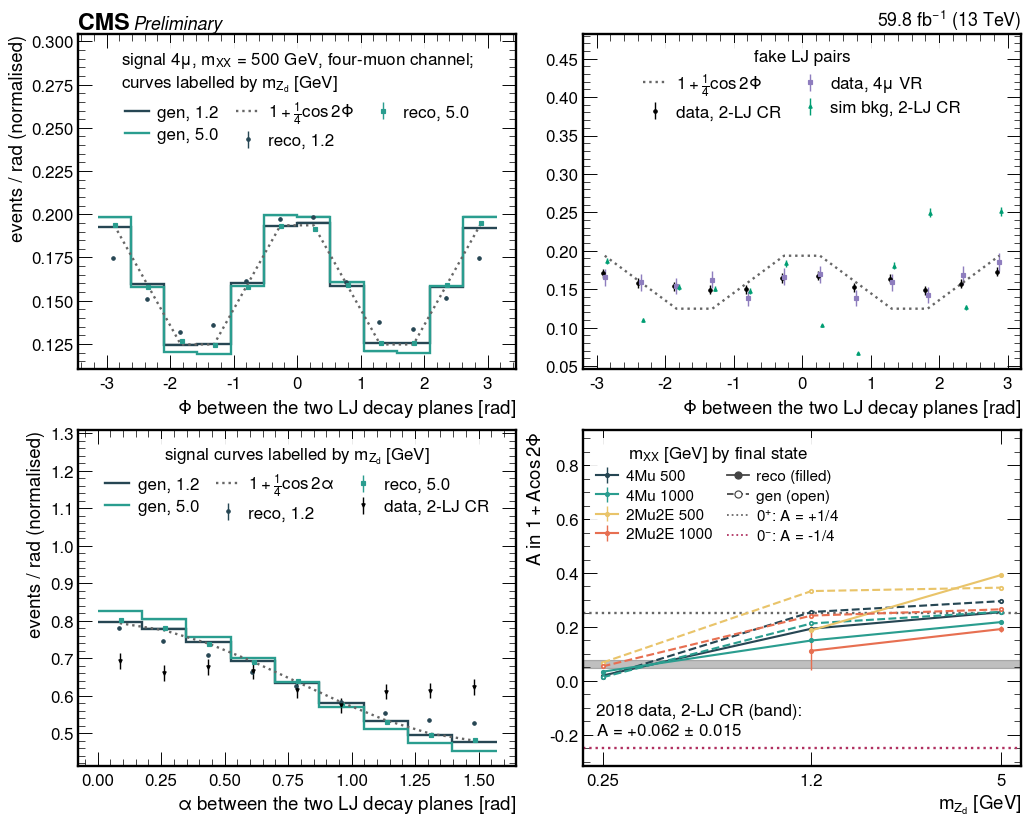

In [45]:
c_phi = lib.fig_pair_planes_phi(points=((500.0, 1.2), (500.0, 5.0)))

In [46]:
phi_rows = lib.planes_phi_table()

A in 1 + A cos(2 Phi), as twice the mean of cos(2 Phi) over the distribution
gen and reco are the same files and the same channel; for the four-muon points
they are also the same events, and for 2mu2e they are not, because a
reconstructed pair needs a resolved electron pair the generated one does not.
set                       channel    N reco             A reco     N gen              A gen  reco/gen
----------------------------------------------------------------------------------------------------
4Mu 100/0.25                  4mu     39987 +0.009 +- 0.007     39987    -0.002 +- 0.007       nan
4Mu 100/1.2                   4mu    100049 +0.282 +- 0.004    100049    +0.355 +- 0.004      0.80


4Mu 100/5.0                   4mu     67857 +0.346 +- 0.005     67857    +0.404 +- 0.005      0.86
4Mu 500/0.25                  4mu    239330 +0.019 +- 0.003    239332    +0.015 +- 0.003       nan
4Mu 500/1.2                   4mu    612290 +0.193 +- 0.002    612290    +0.255 +- 0.002      0.76
4Mu 500/5.0                   4mu    577435 +0.255 +- 0.002    577435    +0.296 +- 0.002      0.86
4Mu 1000/0.25                 4mu    156341 +0.034 +- 0.004    156368    +0.013 +- 0.004       nan
4Mu 1000/1.2                  4mu    424721 +0.150 +- 0.002    424721    +0.213 +- 0.002      0.70
4Mu 1000/5.0                  4mu    450694 +0.218 +- 0.002    450694    +0.256 +- 0.002      0.85
2Mu2E 100/0.25              2mu2e        36 +0.361 +- 0.222      2027    +0.067 +- 0.032      5.37
2Mu2E 100/1.2               2mu2e       606 +0.693 +- 0.051      2881    +0.600 +- 0.024      1.15
2Mu2E 100/5.0               2mu2e       722 +0.690 +- 0.045      2386    +0.504 +- 0.027      1.37
2Mu2E 500/

simulated background     2 LJ invDisp CR     21938 +0.094 +- 0.010           +0.021


How to read these: the generated coefficient is **not** +1/4 at every mass point, and that is the
first thing the figure shows.  For an unselected sample A is the product of the two decays'
analyzing powers, A = [beta*^2 / (3 - beta*^2)]^2: +1/4 for massless leptons, 0.228 for muons at
m_Zd = 1.2 GeV and 0.249 at 5.0 GeV.  At m_XX = 500 GeV the generated value is +0.255 +- 0.002 at
m_Zd = 1.2 GeV and +0.296 +- 0.002 at 5.0 GeV; at m_XX = 100 GeV it rises to +0.355 and +0.404,
above +1/4, the production filter and the selection between them enhancing it; and at
m_Zd = 0.25 GeV it is +0.015 +- 0.003, against 0.011 expected for beta* = 0.53.  The
two-muon-two-electron points follow the same rule with the electron pair's analyzing power of
1/2: 0.052 expected at m_Zd = 0.25 GeV, +0.068 and +0.053 generated at m_XX = 500 and 1000 GeV.
The precision check of section b computes the generated plane angle exactly at every point,
0.25 GeV included, so these generated values are a sound reference, and the analytic curve is
only the limit for an unfiltered sample with massless leptons.

Reconstruction dilutes the coefficient but does not destroy it: the four-muon points retain 70 to
86 percent of their generated value (+0.193 reconstructed against +0.255 generated at
m_XX = 500 GeV, m_Zd = 1.2 GeV; +0.255 against +0.296 at 5.0 GeV; +0.150 against +0.213 and
+0.218 against +0.256 at 1000 GeV).  For the four-muon points the generated and reconstructed
histograms are filled from the **same events** (the two entry counts agree exactly at
m_Zd = 1.2 and 5.0 GeV and differ by at most 27 entries in 156,000 at m_Zd = 0.25 GeV, where a
few events have no negatively charged daughter in the generator record), so that ratio is a
dilution and not an acceptance difference.  For the two-muon-two-electron points they are not the
same events, because a reconstructed pair needs a resolved electron pair that the generated one
does not: at m_XX = 500 GeV, m_Zd = 5.0 GeV the generated histogram holds 183,000 events and the
reconstructed one 54,000, and the reconstructed coefficient there is **larger** than the
generated one, +0.393 +- 0.006 against +0.346 +- 0.003, for that reason alone rather than because
reconstruction improved anything.

What this can and cannot say about a CP-even (0+) against a CP-odd (0-) parent.  It **can** say that the sign of A survives
reconstruction with a dilution of 14 to 30 percent in the four-muon channel at the masses where
beta* is close to one, measured against a generated reference the precision check shows to be
sound there, so a sample of real signal events would show a positive A and a CP-odd parent would show a negative
one, and the two hypotheses are not degenerate after reconstruction.  It **cannot** be read as a
measurement of A: the value depends on the dark-photon mass through beta*, on the production
filter, and on the channel's own acceptance, so any statement about the parent's quantum numbers
needs the efficiency in (theta*, theta*, Phi) mapped out for the point being tested, which this
study does not do.  And the discriminating power against **fakes** is modest and must not be
overstated: the two-lepton-jet control region gives A = +0.062 +- 0.015 on 8,446 events and the
four-muon validation region +0.061 +- 0.028, both positive and both about a quarter of the
signal's.  The simulated background gives +0.094 +- 0.010 counting its unweighted entries and
+0.021 once the cross-section weights are applied; a factor-four swing between those two shows
how little the simulation can settle here, and the numbers below are taken from the data regions
for that reason.  Fakes are not flat in Phi.  The one outlier is the two-muon-two-electron
validation region, A = -0.51 +- 0.15 on 86 events; on that sample size and with that region's
mixed pair composition it is not a result, and more data would be needed to check it.  Caveat 10
of section g explains why that region holds so few events here and sizes the signal in it.

### Do the two lepton jets balance

A real pair comes from one parent, so the two lepton jets should balance in the transverse plane:
a small momentum asymmetry, a small vector sum, and no genuine missing momentum.  A fake pair need
not.  Particle-flow missing momentum does not include displaced-standalone muons, so the
meaningful quantity is the corrected one, the missing-momentum vector with the two leading lepton
jets' displaced-standalone constituents added back.

  wrote sidm/studies/mulj_decay_angle/figures/j6_pair_balance.pdf


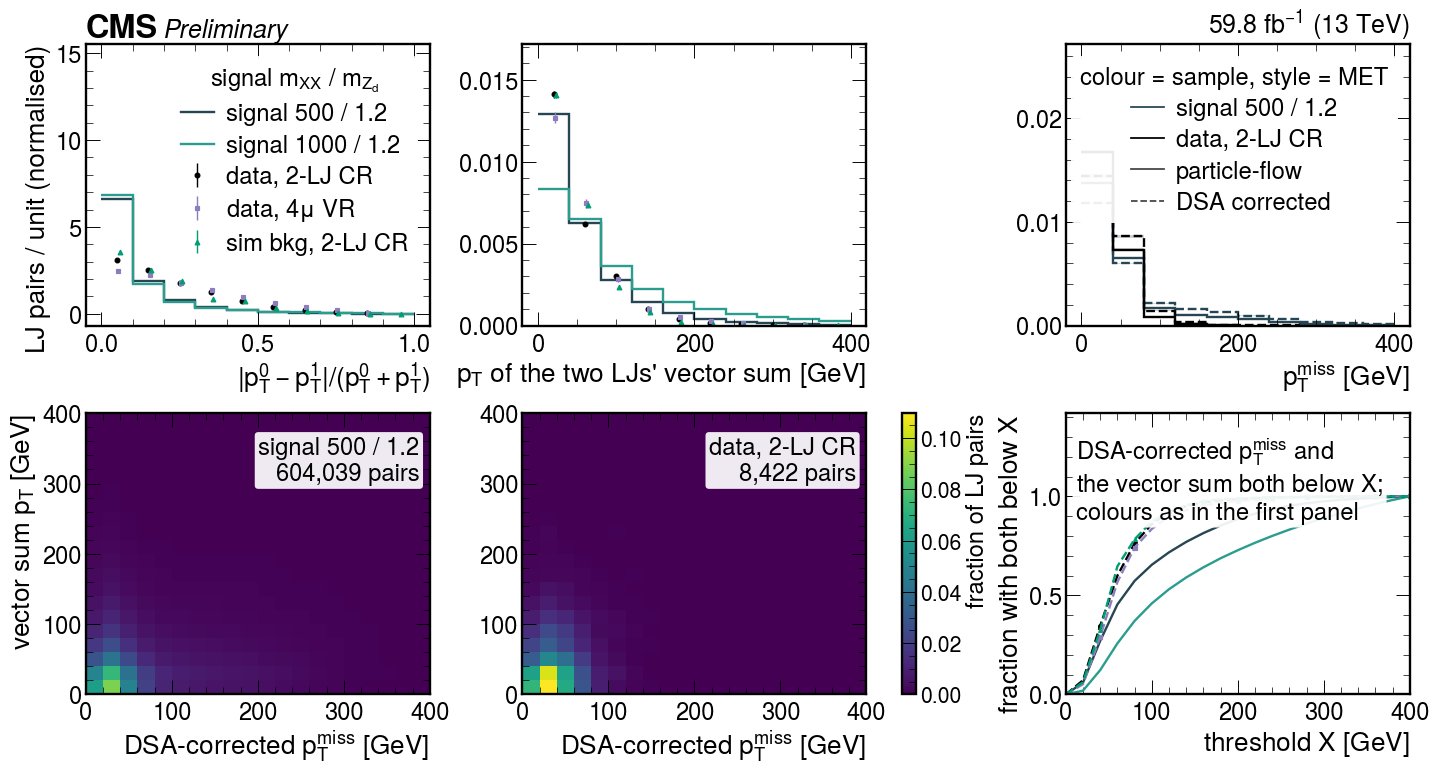

In [47]:
c_balance = lib.fig_pair_balance()

In [48]:
balance_rows = lib.planes_balance_table()

transverse balance and missing momentum of the two leading lepton jets
set                            pairs  ptAsym<0.2  <ptVecSum>  <PF MET>  <corr MET>   corr<40   both<40
--------------------------------------------------------------------------------------------------------
4Mu 500/0.25                  239332      0.8837        53.6      50.9        63.8    0.4728    0.2722
4Mu 500/1.2                   612290      0.8471        58.0      56.4        74.0    0.4712    0.2709
4Mu 500/5.0                   577435      0.8585        55.8      51.4        62.5    0.5401    0.3100
4Mu 1000/0.25                 156368      0.8778        87.6     109.1       126.7    0.2488    0.0947
4Mu 1000/1.2                  424721      0.8525        90.8      93.2       109.4    0.3200    0.1232
4Mu 1000/5.0                  450694      0.8708        85.9      78.4        87.7    0.4014    0.1586
2Mu2E 500/0.25                    45      0.2000       178.6      35.4        45.4    0.5778    0.0227


data, 4mu invDisp VR            2517      0.4648        53.5      35.1        45.4    0.5400    0.2915


sim bkg, two-LJ invDisp CR     21938      0.6101        43.3      40.2        44.1    0.5688    0.3263

The DSA correction subtracts the displaced-standalone constituents of the two
leading lepton jets back out of the missing-momentum vector, so on a signal pair
it should shrink it.  In every set above it does the opposite: read the two mean
columns side by side before using either.


How to read these: **the momentum asymmetry separates and the missing momentum does not.**  A
requirement of ptAsym < 0.2 keeps 0.847 to 0.884 of four-muon signal pairs at m_XX = 500 and
1000 GeV, and 0.874 to 0.905 of the two-muon-two-electron pairs at m_Zd = 5.0 GeV, against 0.560
in the two-lepton-jet control region and 0.465 in the four-muon validation region: a signal
efficiency over root fake efficiency of 1.13 and 1.24.  The weighted simulated background keeps
0.610, more than either data region, so on that sample the requirement separates nothing at all;
its shape is carried by a handful of high-weight simulated events, so the data regions are the
reference.  It is the best single number this section produces, and it is still modest.

The vector sum does not separate at all.  Its mean is 54 to 58 GeV for signal at
m_XX = 500 GeV against 49 GeV in the two-lepton-jet control region and 54 GeV in the
four-muon validation region, and at m_XX = 1000 GeV it is 86 to 91 GeV, **larger** than either
fake sample, because a heavier resonance recoils harder and its 400 to 500 GeV lepton jets carry
a momentum resolution of tens of GeV.  The weighted simulated background is lower still, 43 GeV,
which points the same way and rests on the same handful of high-weight events.

One result to read carefully, because it is the opposite of what the correction was built to do.
The displaced-standalone correction should shrink the missing momentum of a signal pair, and in
every sample here it enlarges it: the mean goes from 51 to 64 GeV at m_XX = 500 GeV, m_Zd = 0.25
GeV, from 78 to 88 GeV at 1000 GeV, m_Zd = 5.0 GeV, from 35 to 41 GeV in the two-lepton-jet control
region and from 40 to 44 GeV in the weighted simulated background: a 10 to 25 percent increase
everywhere, signal and fakes alike. It is a **bulk shift, not a tail effect**: the median moves
from 30.4 to 35.2 GeV in the two-lepton-jet control region and from 35.7 to 42.8 GeV for the m_XX =
500 GeV, m_Zd = 0.25 GeV signal.

The formula is the intended one.  The function `lj_pair_met_observables` subtracts the vector sum of the
displaced-standalone constituents of the **two leading qualifying lepton jets** from the
missing-momentum vector, with the sign that should cancel them, so the premise fails rather than
the code: either those muons' momentum already enters particle-flow missing momentum through
their tracker tracks, or the displaced-standalone momentum resolution adds more than the
subtraction removes.  Histograms cannot separate the two, and **neither the corrected nor the
uncorrected missing momentum is usable until a per-event check is made**; the balance argument
rests on the momentum asymmetry alone.  The last panel makes the same point jointly: the fraction
of pairs with both the corrected missing momentum and the vector sum below a common threshold is
no larger for signal than for the control region at any threshold.

### Summary table

In [49]:
_ = lib.planes_summary_table()

summary, bound-state masses at or above 200 GeV first
(this campaign's grid holds 100, 500 and 1000 GeV only, so the 200 to 250 GeV
range at the low edge of the search is not represented in any row below)

point             mu-LJ eff(|cos|>0.4)  vs 1muLJ CR  vs 2LJ CR  egm 2e frac     A gen    A reco  ptAsym<0.2
------------------------------------------------------------------------------------------------------------
4Mu 500/0.25                    0.5726         1.65       0.87           --    +0.015    +0.019      0.8837
4Mu 500/1.2                     0.6649         1.92       1.01           --    +0.255    +0.193      0.8471
4Mu 500/5.0                     0.6603         1.90       1.00           --    +0.296    +0.255      0.8585


4Mu 1000/0.25                   0.6030         1.74       0.92           --    +0.013    +0.034      0.8778
4Mu 1000/1.2                    0.7084         2.04       1.08           --    +0.213    +0.150      0.8525
4Mu 1000/5.0                    0.6899         1.99       1.05           --    +0.256    +0.218      0.8708
4Mu 100/0.25                    0.6845         1.97       1.04           --    -0.002    +0.009      0.8822
4Mu 100/1.2                     0.6274         1.81       0.95           --    +0.355    +0.282      0.8724
4Mu 100/5.0                     0.6094         1.76       0.93           --    +0.404    +0.346      0.8645
2Mu2E 500/0.25                  0.5632         1.62       0.86      0.00012    +0.068        --          --
2Mu2E 500/1.2                   0.5531         1.59       0.84      0.01579    +0.333    +0.187      0.8459
2Mu2E 500/5.0                   0.5579         1.61       0.85      0.29088    +0.346    +0.393      0.8743
2Mu2E 1000/0.25             

  2018 data, two-LJ invDisp CR: A = +0.062 +- 0.015, r(cos theta_A) = -0.0624 +- 0.0108, ptAsym < 0.2 keeps 0.5600
  2018 data, 4mu invDisp VR: A = +0.061 +- 0.028, r(cos theta_A) = -0.0525 +- 0.0209, ptAsym < 0.2 keeps 0.4648


  simulated bkg, two-LJ CR (weighted): A = +0.021 +- 0.010, r(cos theta_A) = -0.0059 +- 0.0074, ptAsym < 0.2 keeps 0.6101


### Conclusions of section j

1. The decay-plane angle Φ is the one observable in this study that probes the parent rather
   than lepton-jet quality, and it survives reconstruction with the sign the CP-even model
   predicts: in the four-muon channel the coefficient A of cos 2Φ is +0.15 to +0.26 reconstructed
   against +0.21 to +0.30 generated for m_Zd = 1.2 and 5 GeV at m_XX = 500 and 1000 GeV, a
   dilution of 14 to 30 percent,
   against generated values the precision check of section b reproduces exactly.  It is not a
   measurement of A.  For an unselected sample A is the product of the two decays' analyzing
   powers, A = [β*²/(3 − β*²)]², 0.228 at m_Zd = 1.2 GeV and 0.011 at 0.25 GeV (β* = 0.53), where
   the generated value is +0.015 and the planes carry no information; the generated value also
   depends on the production filter and on the channel, so a 0+ against 0- statement would need
   an efficiency map this study does not have.  Against fakes it is weak: the two-lepton-jet
   control region and the four-muon validation region give A = +0.062 +- 0.015 and
   +0.061 +- 0.028, a quarter of the signal value and not zero.

2. Among the regions of this campaign, the per-lepton-jet decay angle separates only against the
   cleaned single-lepton-jet control region (ε_s/√ε_b = 1.9 at |cos θ*| > 0.4) and not against
   the two-lepton-jet control region (1.0), whose topology is the closer match to the signal
   region.
   That region is 59 percent particle-flow pairs, 0.62 of them above the cut, and 41 percent
   mixed pairs, 0.16 above it, so its 0.43 averages two unlike shapes: with the signal
   efficiency unchanged the same cut gives 0.84 against the particle-flow pairs alone and 1.6
   against the mixed ones.  The fake shape depends on the region, which is what section h found,
   and on the pair type.

3. Two resolved electrons in an electromagnetic lepton jet occur in 29 percent of signal jets at
   m_Zd = 5 GeV (m_XX = 500 GeV) against under 1 percent of fakes: a clean but low-efficiency tag
   for that mass family alone.  At m_Zd <= 1.2 GeV the resolved pair exists in at most 1.6 percent
   of jets and cannot be used.

4. Transverse-momentum balance is the most usable new handle and it is modest: ptAsym < 0.2 keeps
   0.85 to 0.90 of signal pairs against 0.56 in the two-lepton-jet control region, ε_s/√ε_b of
   1.1 to 1.2.

5. Missing transverse momentum separates nothing, and the displaced-standalone correction
   increases it in every sample, in the bulk of events and not only in a tail (median 30 -> 35 GeV
   in the two-lepton-jet control region, 36 -> 43 GeV for signal at m_Zd = 0.25 GeV), where a
   signal pair should make it shrink.  The formula is the intended one, the missing-momentum vector
   minus the vector sum of the displaced-standalone constituents of the two leading lepton jets, so
   the premise fails rather than the code: either those muons' momentum already enters particle-flow
   missing momentum through their tracker tracks, or the displaced-standalone momentum resolution
   adds more than the subtraction removes.  Histograms cannot separate the two; neither version of
   the missing momentum is usable until a per-event check is made.

6. The two lepton jets of a fake event are correlated in their signed helicity angles
   (r = -0.062 +- 0.011 with χ² = 309/16 in the two-lepton-jet control region) while four-muon
   signal pairs are not (|r| <= 0.006).  With section i, no factorised estimate over these angles
   may assume independence in fake-dominated regions.  A pair type shared by the two jets cannot
   produce the negative coefficient: with the same angular shape for both jets it gives a
   covariance of zero or above.  Pair types that anti-correlate between the two jets could, and
   the stored histograms do not record both jets' types.  The chi-square part, the joint
   distribution against the product of its marginals, can be compositional even without them:
   the region mixes pair types with unlike shapes (conclusion 2), and two jets of one event that
   share a pair type fail the product test without any angular correlation at fixed type.  The
   study does not separate that part.

7. The simulated background cannot arbitrate any of this: cross-section weights concentrate it in
   a few QCD events and flip its fake shapes (ptAsym < 0.2 keeps 0.33 unweighted, 0.61 weighted).
   The data control regions are the reference throughout.

Net: nothing here changes the search selection.  What the section establishes is the fake-pair
dependence (angular or compositional, which the stored histograms cannot separate), the CP-even
sign of the reconstructed plane correlation with its suppression at low m_Zd, where
A = [β*²/(3 − β*²)]² falls to 0.011, and the histograms that now record these quantities.

## Run record

Everything the run could not draw, and why.  On a complete set of campaign inputs this list should
be short; on a reduced input set it records which panels were left empty.

In [50]:
messages = lib.notes()
print(f"{len(messages)} note(s) recorded during this run")
for message in messages:
    print(" -", message)

4 note(s) recorded during this run
 - signal 2mu2e in 4mu inverted-displacement VR, m_Zd = 0.25 GeV, absCosTheta: 34 entries over 5 bins, below the 50 needed to draw a shape at all; not drawn
 - signal 2mu2e in 4mu inverted-displacement VR, m_Zd = 0.25 GeV, ptRatio: 34 entries over 10 bins, below the 50 needed to draw a shape at all; not drawn
 - signal 2mu2e in 4mu inverted-displacement VR, m_Zd = 5.0 GeV, ptRatio: 3 of 10 bins hold fewer than 5 effective entries and are not drawn
 - data, > 600 GeV: 24 entries over 5 bins, below what this study draws a shape at; not drawn
